# Segmentação de transcrições de call center: experimentação

Este caderno é o registro do que foi explorado, testado e decidido. A ordem é a do trabalho: entender os dados, procurar vazamento, resolver o setor, resolver o subgrupo, e só no fim dizer o que vai para o código de produção.

**O problema.** Entra a transcrição completa de uma chamada. Saem duas coisas:
1. o **setor** (`automotive`, `home_service`, `medicare`), problema supervisionado: o rótulo é a pasta onde o arquivo está;
2. o **subgrupo** dentro do setor previsto, problema sem rótulo: cabe a nós descobrir se existem tipos de chamada dentro de cada setor.

**Como o caderno está organizado**

| Parte | Pergunta que responde |
|---|---|
| 1. Dados | O que tem em cada arquivo? Quantas chamadas são de verdade? |
| 2. Exploração | Como os setores se diferenciam em tamanho, duração, qualidade da transcrição e vocabulário? |
| 3. Vazamento | Existe algum atalho que faria o modelo parecer melhor do que é? |
| 4. Setor | Qual modelo, com qual configuração, e quanto confiar nele? |
| 5. Subgrupos | Existem tipos de chamada dentro de cada setor? Eles se sustentam? |
| 6. Decisão | O que vai para a API e o que fica de limitação? |

**Regras que valem em todo o caderno**
- Tudo que escolhe modelo ou parâmetro usa só o **conjunto de desenvolvimento** (80% das chamadas). O **conjunto de teste** (20%) é aberto uma única vez, na seção 4.13.
- Chamadas com o mesmo identificador nunca ficam em lados diferentes de uma divisão (seção 3 mostra por quê).
- Nenhuma conclusão é escrita antes do número que a sustenta.

## 0. Preparação

Bibliotecas, caminhos e a semente aleatória. Os passos que levam muitos minutos (triagem automática, busca de hiperparâmetros, embeddings, ajuste do modelo pré-treinado) usam o decorador `@cached`, definido abaixo: o resultado da função é guardado em `.cache/notebook/<nome da função>.pkl` e reaproveitado nas execuções seguintes. Se os dados ou os parâmetros do passo mudarem, é preciso apagar o arquivo para recalcular.

In [1]:
import json
import re
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
DATA_DIR = Path("../data")
REPORTS_DIR = Path("../reports")
FIGURES_DIR = REPORTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR = Path("../.cache/notebook")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

SECTORS = ["automotive", "home_service", "medicare"]
SECTOR_COLORS = {"automotive": "#2a6f97", "home_service": "#e07a1f", "medicare": "#5a9e6f"}
metrics = {}  # tudo que os documentos e o painel citam é gravado aqui e salvo na parte 6

sns.set_theme(style="whitegrid", context="notebook", palette=list(SECTOR_COLORS.values()))
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.titleweight": "bold"})


def save_figure(figure, name):
    figure.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")


def cached(function):
    """Guarda em disco o resultado de uma função lenta. Para recalcular, apague o arquivo em .cache/notebook/."""
    def wrapper(*args, **kwargs):
        path = CACHE_DIR / f"{function.__name__}.pkl"
        if path.exists():
            return joblib.load(path)
        result = function(*args, **kwargs)
        joblib.dump(result, path)
        return result
    return wrapper

## 1. Os dados

### 1.1 Leitura dos arquivos

Cada chamada é um JSON com `text` (a transcrição), `confidence` (confiança média da transcrição automática), `audio_duration` (segundos), `words` (cada palavra com início, fim, confiança e `speaker`) e `redacted_pii_policies` (lista das categorias de dado pessoal que foram trocadas por marcadores como `[PERSON_NAME]`).

Dois cuidados na leitura:
- arquivos vazios (0 byte) são pulados e contados;
- o identificador da chamada é a parte hexadecimal do nome do arquivo. Nomes como `abc123_transcript (1).json` ou `abc123_transcript 2.json` são cópias do mesmo identificador `abc123`.

In [2]:
FILE_NAME_PATTERN = re.compile(r"([0-9a-f]+)(.*)\.json$")

records, empty_files = [], []
for sector in SECTORS:
    for path in sorted((DATA_DIR / sector).glob("*.json")):
        raw_bytes = path.read_bytes()
        if not raw_bytes.strip():
            empty_files.append(f"{sector}/{path.name}")
            continue
        document = json.loads(raw_bytes)
        call_id = FILE_NAME_PATTERN.match(path.name).group(1)
        words = document.get("words", [])
        records.append({
            "sector": sector,
            "file_name": path.name,
            "call_id": call_id,
            "is_extra_copy": path.name != f"{call_id}_transcript.json",
            "transcript": document.get("text") or "",
            "asr_confidence": document.get("confidence"),
            "duration_seconds": document.get("audio_duration"),
            "word_count": len(words),
            "low_confidence_word_share": float(np.mean([w["confidence"] < 0.8 for w in words])) if words else np.nan,
            "speaker_filled": any(w.get("speaker") for w in words),
        })

all_files = pd.DataFrame(records)
print(f"{len(all_files)} arquivos lidos, {len(empty_files)} vazios pulados: {empty_files}")
print("Algum arquivo com speaker preenchido:", bool(all_files.speaker_filled.any()))
all_files.drop(columns="transcript").head(3)

10288 arquivos lidos, 2 vazios pulados: ['medicare/1a71fd94e216457a810c1aed95b8bc19 (1)_transcript.json', 'medicare/2c022fdcfe2b4590963829b391e7e4b4_transcript.json']
Algum arquivo com speaker preenchido: False


,sector,file_name,call_id,is_extra_copy,asr_confidence,duration_seconds,word_count,low_confidence_word_share,speaker_filled
0,automotive,0002b72ee53347a5a62b52aaf2526bf4_transcript.json,0002b72ee53347a5a62b52aaf2526bf4,False,0.917354,289,765,0.159477,False
1,automotive,000f939435fa478e9ec79d674e51799c_transcript.json,000f939435fa478e9ec79d674e51799c,False,0.921715,266,269,0.159851,False
2,automotive,0016df8b3a1541f0989e6a7e9dfe92a3_transcript.json,0016df8b3a1541f0989e6a7e9dfe92a3,False,0.950402,689,1062,0.078154,False


### 1.2 Quantas chamadas existem de verdade

O que importa para o modelo é a **chamada**, não o arquivo. A tabela separa os dois e mostra, por setor, o tamanho típico de cada chamada.

In [3]:
sheet = all_files.groupby("sector").agg(
    arquivos=("file_name", "size"),
    chamadas_distintas=("call_id", "nunique"),
    palavras_mediana=("word_count", "median"),
    duracao_mediana_s=("duration_seconds", "median"),
    confianca_mediana=("asr_confidence", "median"),
)
sheet["arquivos_repetidos"] = sheet.arquivos - sheet.chamadas_distintas
sheet.loc["total"] = [sheet.arquivos.sum(), sheet.chamadas_distintas.sum(), np.nan, np.nan, np.nan, sheet.arquivos_repetidos.sum()]
display(sheet.round(3))

ids_in_several_sectors = all_files.groupby("call_id").sector.nunique().gt(1).sum()
print("Identificadores que aparecem em mais de um setor:", ids_in_several_sectors)

,arquivos,chamadas_distintas,palavras_mediana,duracao_mediana_s,confianca_mediana,arquivos_repetidos
sector,,,,,,
automotive,2941.0,2811.0,782.0,377.0,0.950,130.0
home_service,4216.0,4196.0,471.5,267.0,0.887,20.0
medicare,3131.0,3114.0,554.0,311.0,0.883,17.0
total,10288.0,10121.0,NaN,NaN,NaN,167.0


Identificadores que aparecem em mais de um setor: 0


Quando o mesmo identificador aparece em mais de um arquivo, mantemos um só: o arquivo com o nome original (`_transcript.json`), e não a cópia. A partir daqui a tabela se chama `calls` e tem uma linha por chamada.

In [4]:
calls = (all_files.sort_values(["call_id", "is_extra_copy"])
         .drop_duplicates("call_id")
         .reset_index(drop=True))
calls["words_per_minute"] = calls.word_count / (calls.duration_seconds / 60)
calls["char_count"] = calls.transcript.str.len()

identical_text = calls[calls.duplicated("transcript", keep=False)].groupby("transcript").sector.nunique()
print(f"{len(calls)} chamadas distintas")
print(f"{len(identical_text)} textos aparecem em mais de uma chamada (ids diferentes); em mais de um setor: {(identical_text > 1).sum()}")

metrics["dados"] = {
    "arquivos": int(len(all_files)),
    "arquivos_vazios": len(empty_files),
    "chamadas": int(len(calls)),
    "arquivos_repetidos_removidos": int(len(all_files) - len(calls)),
    "por_setor": calls.sector.value_counts().to_dict(),
    "palavras_mediana": calls.groupby("sector").word_count.median().to_dict(),
    "confianca_mediana": calls.groupby("sector").asr_confidence.median().round(3).to_dict(),
    "textos_identicos_com_ids_diferentes": int(len(identical_text)),
}

10121 chamadas distintas
20 textos aparecem em mais de uma chamada (ids diferentes); em mais de um setor: 0


## 2. Exploração

A pergunta desta parte é: o que diferencia os setores além das palavras? Se existir diferença forte em tamanho, duração ou qualidade da transcrição, o modelo pode usá-la como atalho, e isso muda como interpretar o resultado (parte 3).

### 2.1 Balanceamento

,participação,chamadas
sector,,
home_service,0.415,4196
medicare,0.308,3114
automotive,0.278,2811


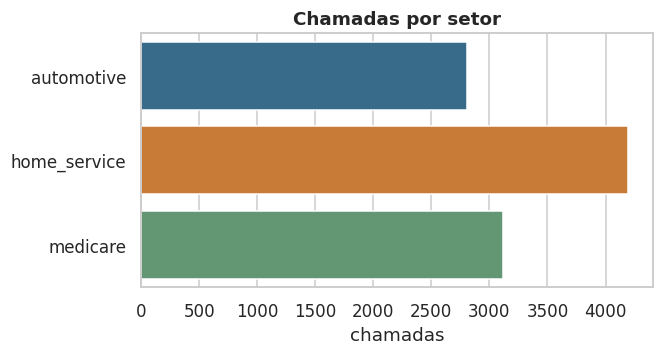

In [5]:
class_share = calls.sector.value_counts(normalize=True).rename("participação").to_frame()
class_share["chamadas"] = calls.sector.value_counts()
display(class_share.round(3))

figure, axis = plt.subplots(figsize=(6, 3))
sns.countplot(data=calls, y="sector", order=SECTORS, hue="sector", legend=False, palette=SECTOR_COLORS, ax=axis)
axis.set(title="Chamadas por setor", xlabel="chamadas", ylabel="")
plt.show()

### 2.2 Distribuição de tamanho, duração e confiança

Violino com caixa dentro: o violino mostra a forma da distribuição (onde há mais chamadas), a caixa mostra mediana e quartis. O eixo de palavras está em escala logarítmica porque a cauda é longa.

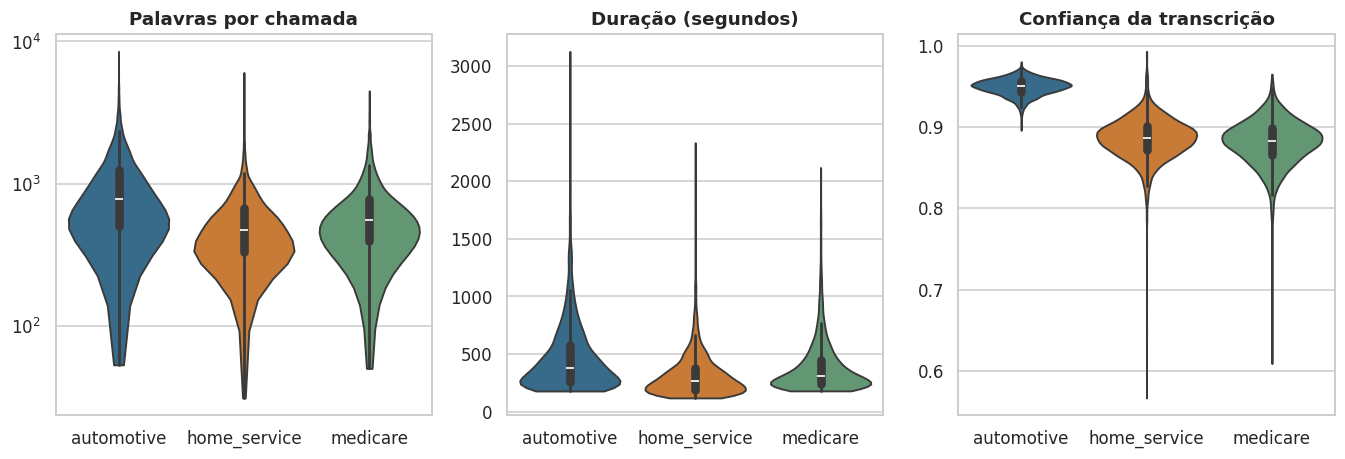

sector                  automotive  home_service  medicare
word_count       count    2811.000      4196.000  3114.000
                 mean      987.445       558.228   668.514
                 std       715.765       354.437   442.868
                 min        53.000        31.000    50.000
                 5%        308.500       217.000   242.000
                 50%       783.000       472.000   554.000
                 95%      2361.500      1158.500  1515.100
                 max      8517.000      6050.000  4493.000
duration_seconds count    2811.000      4196.000  3114.000
                 mean      466.290       315.883   387.811
                 std       298.828       183.323   229.617
                 min       180.000       120.000   181.000
                 5%        191.000       135.000   194.000
                 50%       377.000       267.000   310.000
                 95%      1040.500       651.250   834.450
                 max      3127.000      2334.000  2119.000
asr_confidence   count    2811.000      4196.000  3114.000
                 mean        0.949         0.886     0.881
                 std         0.010         0.025     0.028
                 min         0.896         0.567     0.609
                 5%          0.931         0.846     0.835
                 50%         0.950         0.887     0.883
                 95%         0.964         0.922     0.922
                 max         0.980         0.993     0.965

In [6]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4.5))
panels = [("word_count", "Palavras por chamada", True),
          ("duration_seconds", "Duração (segundos)", False),
          ("asr_confidence", "Confiança da transcrição", False)]
for axis, (column, title, log_scale) in zip(axes, panels):
    sns.violinplot(data=calls, x="sector", y=column, order=SECTORS, hue="sector", legend=False,
                   palette=SECTOR_COLORS, inner="box", cut=0, density_norm="width", ax=axis)
    axis.set(title=title, xlabel="", ylabel="")
    if log_scale:
        axis.set_yscale("log")
plt.show()
save_figure(figure, "distribuicoes_por_setor")

display(calls.groupby("sector")[["word_count", "duration_seconds", "asr_confidence"]]
        .describe(percentiles=[0.05, 0.5, 0.95]).T.round(3))

**Leitura.**
- O automotivo é o menor setor em número de chamadas (2.811), mas tem as chamadas mais longas: mediana de 783 palavras e 377 s, contra 472 e 267 s no home service e 554 e 310 s no medicare. Por isso ele não é o menor em volume de texto.
- A confiança da transcrição do automotivo (mediana 0,950, desvio de apenas 0,010) quase não encosta nos outros dois setores (medianas 0,887 e 0,883). O piso dos 5% mais baixos do automotivo (0,931) fica acima do teto dos 95% mais altos dos outros dois (0,922). Isso é um sinal que identifica o setor sem ler uma palavra, e é um dos suspeitos da parte 3.
- Existe também um piso de duração: nenhuma chamada automotiva ou de medicare dura menos de 180 s, enquanto as de home service começam em 120 s.
- Maior confiança de transcrição não garante que o automotivo seja o setor mais fácil. Só a parte 4 diz isso, com o F1 por setor.

### 2.3 Como tamanho, duração e confiança se relacionam

Correlação de Spearman (mede se uma variável sobe quando a outra sobe, sem supor linha reta), calculada dentro de cada setor para não misturar o efeito do setor com o efeito entre variáveis.

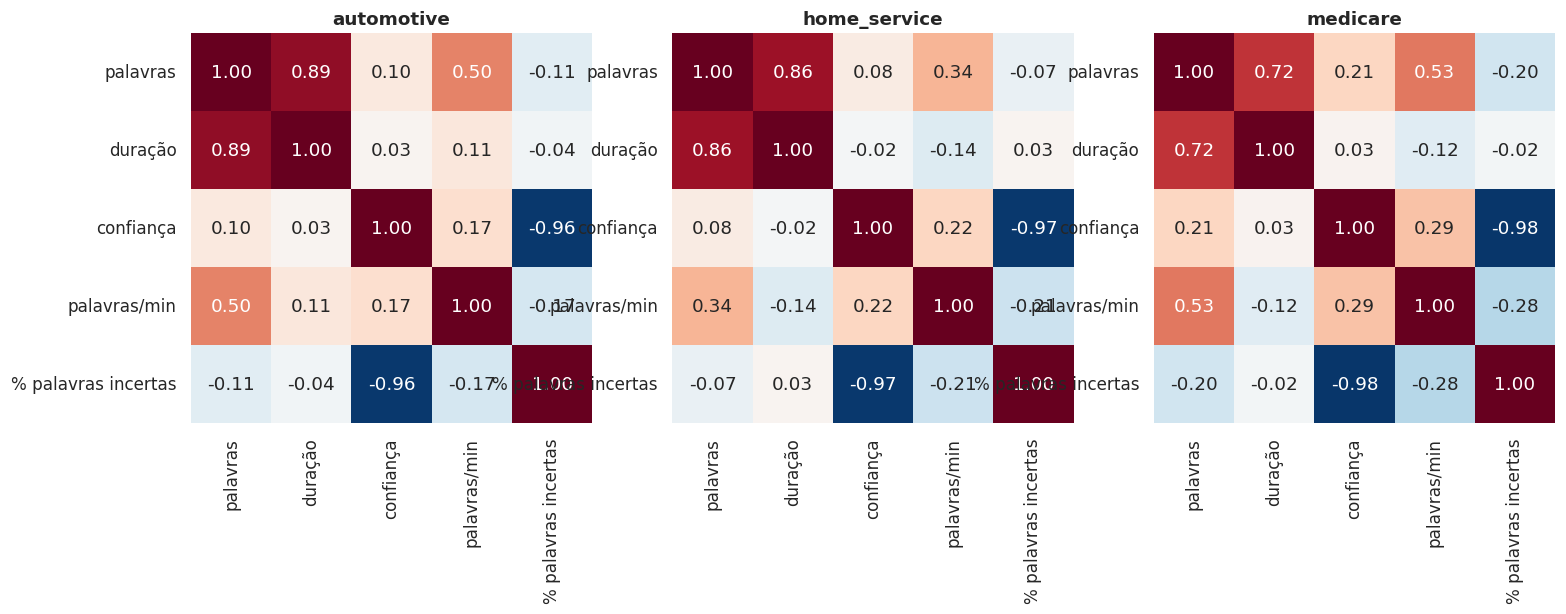

Correlação de Spearman com a confiança da transcrição:


,automotive,home_service,medicare,todas as chamadas juntas
word_count,0.10,0.08,0.21,0.31
duration_seconds,0.03,-0.02,0.03,0.16
words_per_minute,0.17,0.22,0.29,0.35


In [7]:
numeric_columns = ["word_count", "duration_seconds", "asr_confidence", "words_per_minute", "low_confidence_word_share"]
short_names = {"word_count": "palavras", "duration_seconds": "duração", "asr_confidence": "confiança",
               "words_per_minute": "palavras/min", "low_confidence_word_share": "% palavras incertas"}

figure, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for axis, sector in zip(axes, SECTORS):
    corr = calls[calls.sector == sector][numeric_columns].corr(method="spearman").rename(index=short_names, columns=short_names)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, cbar=False, ax=axis)
    axis.set_title(sector)
plt.show()
save_figure(figure, "correlacoes_por_setor")

confidence_correlation = pd.DataFrame({
    sector: calls[calls.sector == sector][["word_count", "duration_seconds", "words_per_minute"]]
    .corrwith(calls[calls.sector == sector].asr_confidence, method="spearman")
    for sector in SECTORS})
confidence_correlation["todas as chamadas juntas"] = calls[["word_count", "duration_seconds", "words_per_minute"]].corrwith(calls.asr_confidence, method="spearman")
print("Correlação de Spearman com a confiança da transcrição:")
display(confidence_correlation.round(2))

**Leitura.**
- Palavras e duração andam juntas em todos os setores (correlação de 0,72 a 0,89): quem fala mais, fala por mais tempo. Por isso as duas carregam quase a mesma informação e uma delas basta num modelo de metadados.
- Dentro de cada setor a confiança quase não depende do tamanho: correlação de 0,03 a 0,21 com a duração e com as palavras. Juntando os setores ela sobe (0,31 com as palavras), mas isso vem do efeito do setor e não da relação entre as variáveis: o automotivo é longo e confiável ao mesmo tempo.
- O ritmo de fala (palavras por minuto) é maior no automotivo (mediana 128) que no home service (109) e no medicare (107).

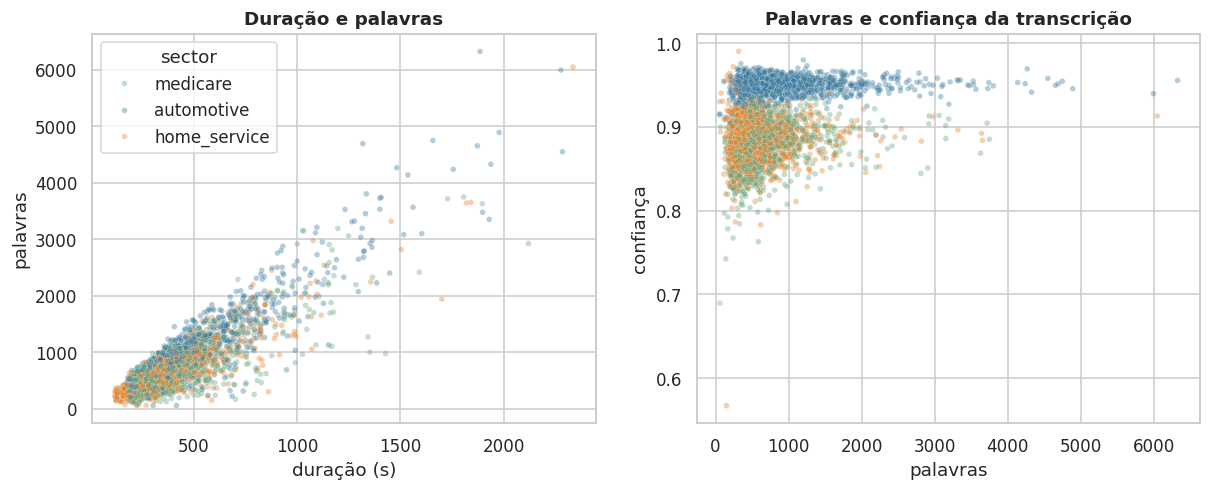

In [8]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.6))
sample = calls.sample(4000, random_state=RANDOM_STATE)
sns.scatterplot(data=sample, x="duration_seconds", y="word_count", hue="sector", palette=SECTOR_COLORS, alpha=0.35, s=14, ax=axes[0])
axes[0].set(title="Duração e palavras", xlabel="duração (s)", ylabel="palavras")
sns.scatterplot(data=sample, x="word_count", y="asr_confidence", hue="sector", palette=SECTOR_COLORS, alpha=0.35, s=14, legend=False, ax=axes[1])
axes[1].set(title="Palavras e confiança da transcrição", xlabel="palavras", ylabel="confiança")
plt.show()

### 2.4 Vocabulário que separa os setores

Para cada palavra, comparamos a fatia de chamadas do setor que a contém com a fatia das outras. O gráfico mostra, por setor, as 12 palavras com maior razão, entre as que aparecem em pelo menos 5% das chamadas do setor.

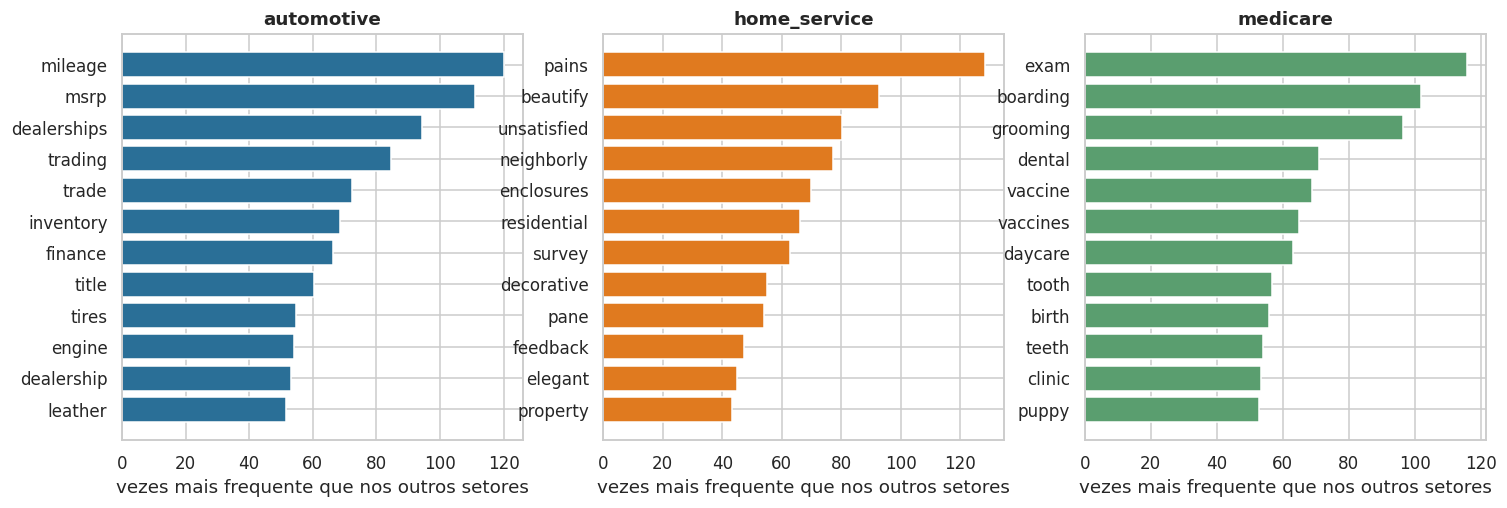

automotive: mileage, msrp, dealerships, trading, trade, inventory, finance, title, tires, engine, dealership, leather
home_service: pains, beautify, unsatisfied, neighborly, enclosures, residential, survey, decorative, pane, feedback, elegant, property
medicare: exam, boarding, grooming, dental, vaccine, vaccines, daycare, tooth, birth, teeth, clinic, puppy


In [9]:
from sklearn.feature_extraction.text import CountVectorizer

presence_vectorizer = CountVectorizer(stop_words="english", min_df=30, binary=True, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
presence = presence_vectorizer.fit_transform(calls.transcript)
vocabulary = np.array(presence_vectorizer.get_feature_names_out())

figure, axes = plt.subplots(1, 3, figsize=(16, 4.8))
distinctive_terms = {}
for axis, sector in zip(axes, SECTORS):
    in_sector = (calls.sector == sector).to_numpy()
    share_in = np.asarray(presence[in_sector].mean(axis=0)).ravel()
    share_out = np.asarray(presence[~in_sector].mean(axis=0)).ravel()
    ratio = (share_in + 0.001) / (share_out + 0.001)
    ratio[share_in < 0.05] = 0
    top = ratio.argsort()[::-1][:12]
    distinctive_terms[sector] = vocabulary[top].tolist()
    axis.barh(vocabulary[top][::-1], ratio[top][::-1], color=SECTOR_COLORS[sector])
    axis.set(title=sector, xlabel="vezes mais frequente que nos outros setores")
plt.show()
save_figure(figure, "vocabulario_por_setor")
for sector, terms in distinctive_terms.items():
    print(f"{sector}: {', '.join(terms)}")

**Leitura.**
- Automotivo: `mileage`, `msrp`, `dealerships`, `trade`, `inventory`, `finance`, `tires`, `engine`. Vocabulário de compra, financiamento e oficina.
- Medicare: `exam`, `dental`, `teeth`, `vaccine` e também `boarding`, `grooming`, `daycare`, `puppy`. O setor mistura saúde de pessoas e serviços para animais de estimação.
- Home service: `pane`, `decorative`, `residential`, `property` (vidro e imóvel) e também `survey`, `feedback`, `unsatisfied` (pesquisa de satisfação).
- Os três setores são, por dentro, misturas de negócios diferentes. É a primeira pista de que o problema dos subgrupos (parte 5) tem estrutura real para achar.

### 2.5 Marcadores de dado pessoal

O texto traz marcadores como `[ORGANIZATION]` e `[PERSON_NAME]` no lugar de dados pessoais. Se um setor tem mais marcadores de um tipo, o modelo pode aprender o marcador e não o assunto. A parte 3 testa isso diretamente; aqui só medimos a frequência.

In [10]:
PII_TAG = re.compile(r"\[([A-Z_]+)\]")
tag_counts = calls.transcript.apply(lambda text: pd.Series(PII_TAG.findall(text)).value_counts())
tag_counts = tag_counts.fillna(0)
tags_per_100_words = tag_counts.div(calls.word_count, axis=0).mul(100)
tags_by_sector = tags_per_100_words.groupby(calls.sector).mean()
top_tags = tags_by_sector.mean().sort_values(ascending=False).head(10).index
display(tags_by_sector[top_tags].round(2).T)

sector,automotive,home_service,medicare
PERSON_NAME,1.70,2.93,2.18
ORGANIZATION,1.84,1.78,1.56
LOCATION,0.50,1.76,0.75
DURATION,0.74,0.50,0.95
TIME,0.27,0.32,0.81
OCCUPATION,0.40,0.57,0.40
DATE,0.09,0.17,0.69
MONEY_AMOUNT,0.42,0.17,0.22
MEDICAL_PROCESS,0.01,0.02,0.74
PHONE_NUMBER,0.24,0.34,0.18


**Leitura.** `MEDICAL_PROCESS` aparece 0,74 vez a cada 100 palavras no medicare e 0,01 a 0,02 nos outros dois; `DATE` é 0,69 no medicare contra 0,09 a 0,17; `LOCATION` é 1,76 no home service contra 0,50 a 0,75. Os marcadores carregam sinal do setor por conta própria, o que justifica o teste da parte 3.

### 2.6 Como as chamadas começam

Muitas chamadas abrem com a mesma frase de gravação ou de espera. Isso importa porque, para o modelo, o começo da chamada pode não ter assunto algum.

In [11]:
opening = calls.transcript.str.split().str[:12].str.join(" ").str.lower()
display(opening.value_counts().head(8).to_frame("chamadas"))
starts_with_greeting = calls.transcript.str.lower().str.startswith(("thank you for calling", "thanks for calling"))
print(f"Chamadas que abrem com agradecimento de ligação: {starts_with_greeting.mean():.1%}")
print(calls.assign(greeting=starts_with_greeting).groupby("sector").greeting.mean().round(3).to_dict())

(saída omitida: trechos de transcrições de terceiros não são publicados)


**Leitura.** 41% das chamadas abrem com "thank you for calling" seguido de marcadores de organização, e as oito aberturas mais comuns são variações do mesmo roteiro. O começo da chamada diz pouco sobre o assunto. A parte 3 testa o quanto o modelo depende dele e a seção 4.11 olha se os erros têm relação com isso.

## 3. Risco de vazamento

Vazamento é quando o modelo recebe, no treino, uma informação que não vai existir na hora de usar, ou um atalho que não tem relação com o problema. O resultado parece ótimo e não se sustenta em chamada nova.

### 3.1 O que pode vazar e como testamos

| # | Suspeita | Por que preocupa | Teste |
|---|---|---|---|
| 1 | A mesma chamada cair no treino e na validação (cópias do arquivo, textos idênticos) | o modelo só reconheceria o que já viu | F1 com divisão por arquivo contra divisão por chamada |
| 2 | Tamanho, duração e confiança da transcrição identificarem o setor | atalho sem relação com o assunto | modelo que usa só esses números |
| 3 | Marcadores como `[ORGANIZATION]` carregarem o setor | o modelo aprenderia o marcador, não o assunto | F1 com e sem marcadores |
| 4 | O roteiro de abertura da chamada | início genérico, sem assunto | F1 usando só o começo, só o fim, e sem o começo |
| 5 | O resultado ser bom demais | sanidade geral | F1 com os rótulos embaralhados deve cair para o acaso (cerca de 0,33) |
| 6 | O vocabulário do TF-IDF ser ajustado com dados de validação | vazamento clássico de pré-processamento | evitado por construção: o vetorizador está dentro do pipeline e é ajustado só no treino de cada dobra |

### 3.2 Divisão dos dados usada no resto do caderno

Separamos 20% das chamadas como **teste**, que só será aberto na seção 4.13. O restante é o **desenvolvimento**, onde toda escolha é feita por validação cruzada em 5 dobras, estratificada por setor.

Chamadas com texto idêntico recebem o mesmo grupo e nunca ficam em lados diferentes de uma divisão.

In [12]:
from sklearn.model_selection import StratifiedGroupKFold

calls["group"] = pd.factorize(calls.transcript)[0]

holdout_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
development_index, test_index = next(holdout_splitter.split(calls, calls.sector, calls.group))
development = calls.iloc[development_index].reset_index(drop=True)
test = calls.iloc[test_index].reset_index(drop=True)

print(f"desenvolvimento: {len(development)} chamadas | teste: {len(test)} chamadas")
print("grupos em comum entre os dois:", len(set(development.group) & set(test.group)))
display(pd.concat({"desenvolvimento": development.sector.value_counts(normalize=True),
                   "teste": test.sector.value_counts(normalize=True)}, axis=1).round(3))

desenvolvimento: 8094 chamadas | teste: 2027 chamadas
grupos em comum entre os dois: 0


,desenvolvimento,teste
sector,,
home_service,0.413,0.420
medicare,0.308,0.305
automotive,0.278,0.275


### 3.3 Ferramentas dos testes

Um único modelo de referência, TF-IDF de palavras e pares de palavras seguido de SVM linear, avaliado por validação cruzada. O mesmo modelo serve em todos os testes, para que a diferença venha do que mudou nos dados e não do algoritmo.

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

TFIDF_SETTINGS = dict(min_df=3, max_df=0.9, sublinear_tf=True, ngram_range=(1, 2), max_features=200_000)
cross_validation = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def reference_model():
    return make_pipeline(TfidfVectorizer(**TFIDF_SETTINGS), LinearSVC(C=1.0))


def cross_validated_f1(model, features, labels=None, groups=None, n_jobs=3):
    """F1 macro médio e desvio entre as 5 dobras; as dobras respeitam os grupos de texto idêntico."""
    labels = development.sector if labels is None else labels
    groups = development.group if groups is None else groups
    scores = cross_val_score(model, features, labels, groups=groups, cv=cross_validation,
                             scoring="f1_macro", n_jobs=n_jobs)
    return scores.mean(), scores.std()


leakage_results = []


def record(test_name, mean, std, note=""):
    leakage_results.append({"teste": test_name, "F1 macro": round(mean, 4), "desvio entre dobras": round(std, 4), "observação": note})
    print(f"{test_name}: F1 macro {mean:.4f} (desvio {std:.4f})")

### 3.4 Teste 0: o modelo de referência com tudo

É a régua dos outros testes.

In [14]:
started = time.time()
reference_mean, reference_std = cross_validated_f1(reference_model(), development.transcript)
record("0. referência (texto completo)", reference_mean, reference_std)
print(f"{time.time() - started:.0f} s")

0. referência (texto completo): F1 macro 0.9935 (desvio 0.0015)
13 s


### 3.5 Teste 1: cópias do mesmo arquivo

Pegamos todos os arquivos das chamadas de desenvolvimento, **inclusive as cópias**, e comparamos duas divisões: aleatória por arquivo (uma chamada pode ter uma cópia no treino e outra na validação) e agrupada por identificador da chamada.

In [15]:
from sklearn.model_selection import StratifiedKFold

files_of_development = all_files[all_files.call_id.isin(development.call_id) & (all_files.transcript.str.strip() != "")]
by_file = cross_val_score(reference_model(), files_of_development.transcript, files_of_development.sector,
                          cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="f1_macro", n_jobs=3)
by_call = cross_val_score(reference_model(), files_of_development.transcript, files_of_development.sector,
                          groups=files_of_development.call_id, cv=cross_validation, scoring="f1_macro", n_jobs=3)
record("1a. divisão por arquivo (cópias soltas)", by_file.mean(), by_file.std(), f"{len(files_of_development)} arquivos")
record("1b. divisão por chamada", by_call.mean(), by_call.std())
print(f"inflação por vazamento de cópias: {by_file.mean() - by_call.mean():+.4f}")

1a. divisão por arquivo (cópias soltas): F1 macro 0.9929 (desvio 0.0016)
1b. divisão por chamada: F1 macro 0.9935 (desvio 0.0010)
inflação por vazamento de cópias: -0.0006


### 3.6 Teste 2: só metadados

Treinamos um modelo que nunca vê o texto. As variáveis são: palavras, caracteres, duração, ritmo de fala, confiança média e fatia de palavras com confiança baixa. Se ele acertar muito acima do acaso, existe um atalho.

In [16]:
from sklearn.ensemble import HistGradientBoostingClassifier

metadata_columns = ["word_count", "char_count", "duration_seconds", "words_per_minute", "asr_confidence", "low_confidence_word_share"]
metadata_mean, metadata_std = cross_validated_f1(HistGradientBoostingClassifier(random_state=RANDOM_STATE),
                                                 development[metadata_columns])
record("2. só metadados", metadata_mean, metadata_std, "sem ler o texto")

only_confidence = cross_validated_f1(HistGradientBoostingClassifier(random_state=RANDOM_STATE), development[["asr_confidence"]])
record("2b. só confiança da transcrição", *only_confidence)
only_duration = cross_validated_f1(HistGradientBoostingClassifier(random_state=RANDOM_STATE), development[["duration_seconds"]])
record("2c. só duração", *only_duration)

2. só metadados: F1 macro 0.7108 (desvio 0.0076)


2b. só confiança da transcrição: F1 macro 0.6427 (desvio 0.0100)


2c. só duração: F1 macro 0.4237 (desvio 0.0137)


### 3.7 Teste 3: sem os marcadores de dado pessoal

In [17]:
without_tags = development.transcript.str.replace(PII_TAG, " ", regex=True)
record("3. sem marcadores [TAG]", *cross_validated_f1(reference_model(), without_tags))

3. sem marcadores [TAG]: F1 macro 0.9932 (desvio 0.0015)


### 3.8 Teste 4: começo, fim e meio da chamada

In [18]:
words_of_call = development.transcript.str.split()
for name, text in {
    "4a. só as primeiras 60 palavras": words_of_call.str[:60].str.join(" "),
    "4b. só as últimas 60 palavras": words_of_call.str[-60:].str.join(" "),
    "4c. sem as primeiras 60 palavras": words_of_call.str[60:].str.join(" "),
}.items():
    record(name, *cross_validated_f1(reference_model(), text))

4a. só as primeiras 60 palavras: F1 macro 0.9541 (desvio 0.0060)


4b. só as últimas 60 palavras: F1 macro 0.8165 (desvio 0.0032)


4c. sem as primeiras 60 palavras: F1 macro 0.9837 (desvio 0.0017)


### 3.9 Teste 5: rótulos embaralhados

Se os rótulos forem trocados ao acaso, o modelo não tem o que aprender. O F1 deve cair para o acaso. Se não cair, há um defeito no procedimento de validação.

In [19]:
shuffled_labels = pd.Series(np.random.default_rng(RANDOM_STATE).permutation(development.sector.to_numpy()))
record("5. rótulos embaralhados", *cross_validated_f1(reference_model(), development.transcript, labels=shuffled_labels),
       "esperado: cerca de 0,33")

5. rótulos embaralhados: F1 macro 0.3307 (desvio 0.0086)


In [20]:
leakage_table = pd.DataFrame(leakage_results)
display(leakage_table)
metrics["vazamento"] = {row["teste"]: row["F1 macro"] for row in leakage_results}
metrics["vazamento_inflacao_copias"] = round(float(by_file.mean() - by_call.mean()), 4)

,teste,F1 macro,desvio entre dobras,observação
0,0. referência (texto completo),0.9935,0.0015,
1,1a. divisão por arquivo (cópias soltas),0.9929,0.0016,8216 arquivos
2,1b. divisão por chamada,0.9935,0.0010,
3,2. só metadados,0.7108,0.0076,sem ler o texto
4,2b. só confiança da transcrição,0.6427,0.0100,
5,2c. só duração,0.4237,0.0137,
6,3. sem marcadores [TAG],0.9932,0.0015,
7,4a. só as primeiras 60 palavras,0.9541,0.0060,
8,4b. só as últimas 60 palavras,0.8165,0.0032,
9,4c. sem as primeiras 60 palavras,0.9837,0.0017,


### 3.10 Leitura dos testes

- **Teste 0, referência:** F1 macro de 0,9935 (desvio entre dobras de 0,0015) com o texto completo.
- **Teste 1, cópias:** dividir por arquivo deu 0,9929 e dividir por chamada deu 0,9935. A diferença (0,0006) é menor que o desvio entre dobras, então as cópias não inflam o resultado. Mesmo assim mantemos a divisão por grupo, porque ela não custa nada e protege contra o caso em que as cópias fossem mais numerosas.
- **Teste 2, metadados:** sem ler uma palavra, o modelo chega a 0,7108 de F1 macro, contra 0,33 do acaso. Só a confiança da transcrição dá 0,6427; só a duração dá 0,4237. Existe um atalho, mas ele está longe do 0,9935 do texto. A seção 4.7 testa se somar os metadados ao texto melhora alguma coisa.
- **Teste 3, marcadores:** sem os marcadores o F1 é 0,9932, igual ao da referência dentro do desvio. O modelo não depende deles.
- **Teste 4, partes da chamada:** só as primeiras 60 palavras dão 0,9541; só as últimas 60 dão 0,8165; sem as primeiras 60 o F1 é 0,9837. O começo ajuda (perder as 60 primeiras palavras custa 0,0098), mas o resto da chamada sozinho já classifica quase tão bem.
- **Teste 5, rótulos embaralhados:** 0,3307, o esperado para três classes quase equilibradas. O procedimento de validação não está produzindo acerto do nada.

**Conclusão.** Não encontramos vazamento que explique o resultado. O atalho de metadados existe e fica registrado como limitação, mas o desempenho vem do texto. A consequência prática é que o teto de qualidade do setor é alto (perto de 0,99), e as diferenças entre modelos serão pequenas: um bom modelo de texto erra algumas dezenas de chamadas em mais de dez mil.

## 4. Setor: qual modelo, com qual configuração, e quanto confiar

### 4.1 Como vamos medir

- **Métrica: F1 macro.** É a média do F1 de cada setor, sem peso pelo tamanho. O home service tem 41% das chamadas e o automotivo 28%; a média simples não deixa um setor grande esconder erro num pequeno.
- **Validação: 5 dobras estratificadas e agrupadas** (seção 3.2), sempre dentro do desenvolvimento. Cada chamada é validada uma vez, por um modelo que não a viu.
- **Diagnóstico de ajuste.** Medimos o F1 no treino e na validação. Treino muito acima da validação indica **sobreajuste** (o modelo decorou); os dois baixos indicam **subajuste** (o modelo é simples demais). Também observamos como o F1 de validação muda com mais dados (curva de aprendizado) e com a força da regularização.
- **Regra de escolha, fixada antes de ver o teste.** Vence o maior F1 médio de validação. Se a diferença para um modelo mais simples e mais rápido for menor que o desvio entre dobras, fica o mais simples.

A representação do texto é o TF-IDF: cada chamada vira um vetor com o peso de cada palavra e de cada par de palavras, maior para termos frequentes na chamada e raros nas outras. O vetorizador é ajustado **dentro** de cada dobra, só com o treino dela.

In [21]:
from sklearn.metrics import f1_score


def build_fold_matrices(texts, labels, groups, vectorizer_settings=TFIDF_SETTINGS):
    """Para cada dobra: índices, matriz TF-IDF do treino e da validação (vetorizador ajustado só no treino)."""
    folds = []
    for train_index, valid_index in cross_validation.split(texts, labels, groups):
        vectorizer = TfidfVectorizer(**vectorizer_settings)
        folds.append({
            "train_index": train_index, "valid_index": valid_index,
            "X_train": vectorizer.fit_transform(texts.iloc[train_index]),
            "X_valid": vectorizer.transform(texts.iloc[valid_index]),
        })
    return folds


def score_on_folds(make_model, folds, labels):
    """F1 macro de treino e de validação, por dobra, e o tempo de ajuste."""
    rows = []
    for fold in folds:
        model = make_model()
        started = time.time()
        model.fit(fold["X_train"], labels.iloc[fold["train_index"]])
        fit_seconds = time.time() - started
        rows.append({
            "train_f1": f1_score(labels.iloc[fold["train_index"]], model.predict(fold["X_train"]), average="macro"),
            "valid_f1": f1_score(labels.iloc[fold["valid_index"]], model.predict(fold["X_valid"]), average="macro"),
            "fit_seconds": fit_seconds,
        })
    return pd.DataFrame(rows)


started = time.time()
folds = build_fold_matrices(development.transcript, development.sector, development.group)
print(f"matrizes TF-IDF das 5 dobras prontas em {time.time() - started:.0f} s; "
      f"vocabulário de cada dobra: {folds[0]['X_train'].shape[1]} termos")

matrizes TF-IDF das 5 dobras prontas em 22 s; vocabulário de cada dobra: 116707 termos


### 4.2 Pontos de comparação

Antes de qualquer modelo elaborado, três referências: sempre prever a classe mais comum, usar só metadados (resultado da seção 3) e o TF-IDF com regressão logística sem ajuste fino. Um modelo só merece complexidade se ganhar de todas.

In [22]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

comparison = {}
for name, make_model in {
    "sempre a classe mais comum": lambda: DummyClassifier(strategy="most_frequent"),
    "TF-IDF + regressão logística (C=5)": lambda: LogisticRegression(C=5.0, max_iter=3000),
}.items():
    scores = score_on_folds(make_model, folds, development.sector)
    comparison[name] = scores
    print(f"{name}: validação {scores.valid_f1.mean():.4f} ± {scores.valid_f1.std():.4f} | treino {scores.train_f1.mean():.4f}")
print(f"só metadados (seção 3): {metadata_mean:.4f} ± {metadata_std:.4f}")

sempre a classe mais comum: validação 0.1949 ± 0.0014 | treino 0.1949


TF-IDF + regressão logística (C=5): validação 0.9909 ± 0.0032 | treino 0.9998
só metadados (seção 3): 0.7108 ± 0.0076


**Leitura.** Sempre prever a classe mais comum dá F1 macro de 0,1949; só os metadados, 0,7108; TF-IDF com regressão logística sem ajuste fino, 0,9909. A régua para qualquer modelo mais elaborado é, portanto, 0,99: quase todo o ganho possível já está no baseline simples, e o que resta a disputar são poucas dezenas de chamadas.

### 4.3 Sobreajuste e subajuste

Duas figuras para a regressão logística e depois para o SVM linear.

**Curva de validação:** o F1 de treino e de validação conforme a força da regularização. No SVM linear e na regressão logística, `C` pequeno regulariza muito (modelo simples) e `C` grande quase não regulariza (modelo flexível).

**Curva de aprendizado:** o F1 de validação conforme o tamanho do conjunto de treino. Se a curva ainda sobe no fim, mais dados ajudariam; se achatou, o limite é o modelo ou o ruído dos rótulos.

,C,treino,validação,desvio da validação
0,0.01,0.9722,0.9642,0.0071
1,0.03,0.9889,0.9804,0.0032
2,0.10,0.9968,0.9892,0.0026
3,0.30,0.9996,0.9922,0.0031
4,1.00,1.0000,0.9935,0.0017
5,3.00,1.0000,0.9935,0.0014
6,10.00,1.0000,0.9936,0.0014
7,30.00,1.0000,0.9936,0.0014
8,100.00,1.0000,0.9936,0.0014


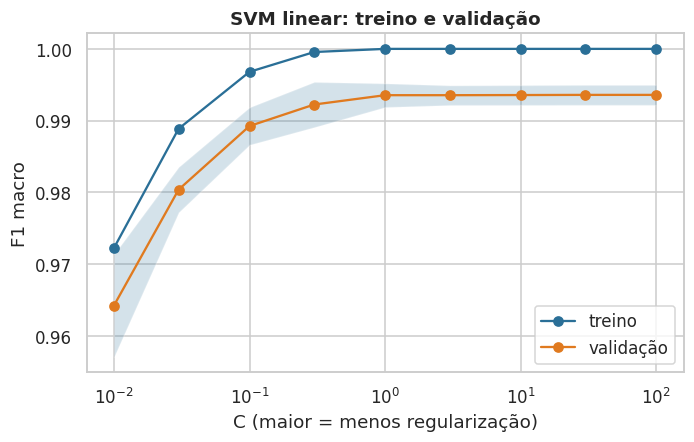

In [23]:
regularization_values = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]
validation_curve_rows = []
for c_value in regularization_values:
    scores = score_on_folds(lambda: LinearSVC(C=c_value), folds, development.sector)
    validation_curve_rows.append({"C": c_value, "treino": scores.train_f1.mean(), "validação": scores.valid_f1.mean(),
                                  "desvio da validação": scores.valid_f1.std()})
validation_curve = pd.DataFrame(validation_curve_rows)
display(validation_curve.round(4))

figure, axis = plt.subplots(figsize=(7, 4))
axis.plot(validation_curve.C, validation_curve["treino"], marker="o", label="treino")
axis.plot(validation_curve.C, validation_curve["validação"], marker="o", label="validação")
axis.fill_between(validation_curve.C, validation_curve["validação"] - validation_curve["desvio da validação"],
                  validation_curve["validação"] + validation_curve["desvio da validação"], alpha=0.2)
axis.set(xscale="log", xlabel="C (maior = menos regularização)", ylabel="F1 macro", title="SVM linear: treino e validação")
axis.legend()
plt.show()
save_figure(figure, "curva_de_validacao_svm")

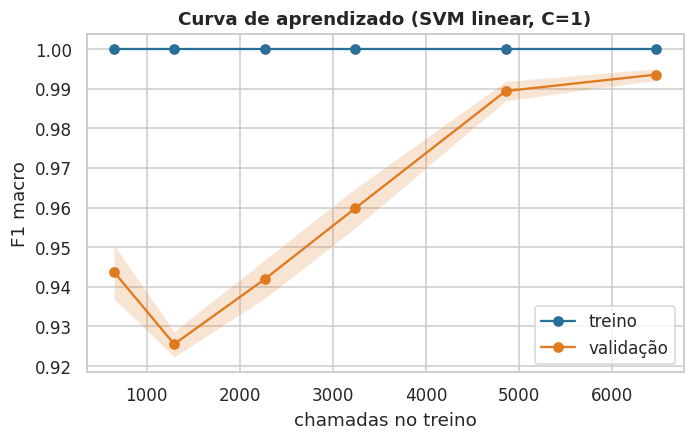

,chamadas no treino,treino,validação
0,647,1.0,0.9438
1,1295,1.0,0.9255
2,2266,1.0,0.9419
3,3237,1.0,0.9598
4,4856,1.0,0.9894
5,6475,1.0,0.9935


In [24]:
from sklearn.model_selection import learning_curve

train_fractions = [0.1, 0.2, 0.35, 0.5, 0.75, 1.0]
sizes, train_curve, valid_curve = learning_curve(
    make_pipeline(TfidfVectorizer(**TFIDF_SETTINGS), LinearSVC(C=1.0)),
    development.transcript, development.sector, groups=development.group, cv=cross_validation,
    train_sizes=train_fractions, scoring="f1_macro", n_jobs=3)

figure, axis = plt.subplots(figsize=(7, 4))
for curve, label in [(train_curve, "treino"), (valid_curve, "validação")]:
    axis.plot(sizes, curve.mean(axis=1), marker="o", label=label)
    axis.fill_between(sizes, curve.mean(axis=1) - curve.std(axis=1), curve.mean(axis=1) + curve.std(axis=1), alpha=0.2)
axis.set(xlabel="chamadas no treino", ylabel="F1 macro", title="Curva de aprendizado (SVM linear, C=1)")
axis.legend()
plt.show()
save_figure(figure, "curva_de_aprendizado_svm")
pd.DataFrame({"chamadas no treino": sizes, "treino": train_curve.mean(axis=1).round(4), "validação": valid_curve.mean(axis=1).round(4)})

**Leitura.**
- **Subajuste:** com `C = 0,01` (regularização forte) o F1 é 0,9722 no treino e 0,9642 na validação. O modelo é simples demais e perde.
- **Sobreajuste:** a partir de `C = 1` o F1 de treino é 1,0000 (o modelo decora o treino) e o de validação chega a 0,9935 e estaciona, em 0,9936 até `C = 100`. A distância treino-validação é de cerca de 0,0065. Num modelo linear com mais de cem mil atributos isso é esperado e não prejudica: o sinal de sobreajuste que importa é a validação **piorar** quando a regularização diminui, e ela não piora.
- **Mais dados ajudam:** a curva de aprendizado ainda sobe no fim. Com 1.295 chamadas no treino a validação é 0,9255; com 4.856, 0,9894; com 6.475, 0,9935. Isso sustenta o retreino periódico quando chegam chamadas novas.

### 4.4 Comparando famílias de modelos

Com os mesmos atributos TF-IDF e as mesmas 5 dobras, comparamos algoritmos diferentes. Para todos mostramos o F1 de validação com o desvio entre dobras, o F1 de treino (a distância entre os dois é o sinal de sobreajuste) e o tempo de ajuste.

In [25]:
from sklearn.linear_model import RidgeClassifier, SGDClassifier
from sklearn.naive_bayes import ComplementNB

family_candidates = {
    "SVM linear (C=0.5)": lambda: LinearSVC(C=0.5),
    "SVM linear (C=5)": lambda: LinearSVC(C=5.0),
    "Regressão logística (C=5)": lambda: LogisticRegression(C=5.0, max_iter=3000),
    "Regressão logística (C=100)": lambda: LogisticRegression(C=100.0, max_iter=3000),
    "SGD (perda modified_huber)": lambda: SGDClassifier(loss="modified_huber", alpha=1e-5, random_state=RANDOM_STATE),
    "Ridge (alpha=1)": lambda: RidgeClassifier(alpha=1.0),
    "Naive Bayes complementar (alpha=0.3)": lambda: ComplementNB(alpha=0.3),
}
family_rows = []
for name, make_model in family_candidates.items():
    scores = score_on_folds(make_model, folds, development.sector)
    family_rows.append({"modelo": name, "F1 validação": scores.valid_f1.mean(), "desvio": scores.valid_f1.std(),
                        "F1 treino": scores.train_f1.mean(), "segundos por ajuste": scores.fit_seconds.mean()})
family_table = pd.DataFrame(family_rows).sort_values("F1 validação", ascending=False)
family_table["distância treino - validação"] = family_table["F1 treino"] - family_table["F1 validação"]
display(family_table.round(4).reset_index(drop=True))

,modelo,F1 validação,desvio,F1 treino,segundos por ajuste,distância treino - validação
0,Ridge (alpha=1),0.9938,0.0013,0.9998,1.0517,0.0060
1,SVM linear (C=5),0.9936,0.0014,1.0000,1.0152,0.0064
2,SVM linear (C=0.5),0.9926,0.0025,0.9998,0.3795,0.0071
3,Regressão logística (C=100),0.9925,0.0036,1.0000,5.0946,0.0075
4,SGD (perda modified_huber),0.9920,0.0038,1.0000,0.1861,0.0080
5,Regressão logística (C=5),0.9909,0.0032,0.9998,5.5256,0.0089
6,Naive Bayes complementar (alpha=0.3),0.9835,0.0016,0.9929,0.0284,0.0094


**Leitura.** Ridge (0,9938) e SVM linear com `C = 5` (0,9936) empatam dentro do desvio entre dobras (0,0013 e 0,0014). A regressão logística fica em 0,9909 com `C = 5` e 0,9925 com `C = 100`, e o Naive Bayes complementar em 0,9835. O treino chega perto de 1,0 em todos; a maior distância para a validação (0,0094) é a do Naive Bayes.

### 4.5 Triagem automática com LazyPredict

A ferramenta ajusta dezenas de classificadores do scikit-learn com configuração padrão e ordena por desempenho. Serve como triagem para não deixar de olhar uma família, não como resultado final: ela usa **uma única** divisão e não ajusta hiperparâmetros.

Como a maioria desses algoritmos não aceita matrizes com 200 mil colunas, os textos passam antes por uma redução para 300 dimensões (SVD sobre o TF-IDF). Usamos a primeira dobra (treino e validação já definidos). A função é guardada em disco porque leva muitos minutos.

In [26]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize


@cached
def lazy_predict_screening(texts_train, labels_train, texts_valid, labels_valid):
    from lazypredict.Supervised import LazyClassifier

    vectorizer = TfidfVectorizer(**TFIDF_SETTINGS).fit(texts_train)
    reducer = TruncatedSVD(300, random_state=RANDOM_STATE).fit(vectorizer.transform(texts_train))
    reduce = lambda texts: normalize(reducer.transform(vectorizer.transform(texts)))  # noqa: E731
    lazy = LazyClassifier(verbose=0, ignore_warnings=True, random_state=RANDOM_STATE, predictions=True)
    scores, predictions = lazy.fit(reduce(texts_train), reduce(texts_valid), labels_train, labels_valid)
    scores = scores.reset_index().rename(columns={"index": "Model"})
    scores["F1 macro"] = [f1_score(labels_valid, predictions[name], average="macro") for name in scores.Model]
    return scores.sort_values("F1 macro", ascending=False).reset_index(drop=True)


first_fold = folds[0]
started = time.time()
lazy_scores = lazy_predict_screening(
    development.transcript.iloc[first_fold["train_index"]].tolist(), development.sector.iloc[first_fold["train_index"]].tolist(),
    development.transcript.iloc[first_fold["valid_index"]].tolist(), development.sector.iloc[first_fold["valid_index"]].tolist())
print(f"{len(lazy_scores)} classificadores avaliados ({time.time() - started:.0f} s nesta execução)")
display(lazy_scores[["Model", "F1 macro", "Accuracy", "Time Taken"]].head(12).round(4))
display(lazy_scores[["Model", "F1 macro"]].tail(5).round(4))

26 classificadores avaliados (0 s nesta execução)


,Model,F1 macro,Accuracy,Time Taken
0,RidgeClassifier,0.9900,0.9901,0.1102
1,LinearDiscriminantAnalysis,0.9900,0.9901,5.5170
2,RidgeClassifierCV,0.9900,0.9901,1.1114
3,NuSVC,0.9895,0.9895,6.0198
4,SVC,0.9893,0.9895,3.9744
5,SGDClassifier,0.9888,0.9889,0.2289
6,CalibratedClassifierCV,0.9887,0.9889,3.4222
7,LinearSVC,0.9880,0.9883,0.8801
8,Perceptron,0.9868,0.9870,0.1923
9,PassiveAggressiveClassifier,0.9867,0.9870,0.2027


,Model,F1 macro
21,GaussianNB,0.8617
22,ExtraTreeClassifier,0.7199
23,DummyClassifier,0.1955
24,LabelSpreading,0.1828
25,LabelPropagation,0.1828


**Leitura.** Dos 26 classificadores, três empatam no topo com 0,9900 (`RidgeClassifier`, `LinearDiscriminantAnalysis`, `RidgeClassifierCV`), seguidos de `NuSVC` e `SVC` (0,9895 e 0,9893). Os modelos de árvores ficam abaixo (`LGBMClassifier` 0,9763, `RandomForestClassifier` 0,9628) e o `KNeighborsClassifier` em 0,8646. O `DummyClassifier` (0,1955) confirma a régua do acaso. Esta triagem usa uma única divisão e o TF-IDF reduzido a 300 dimensões, por isso seus números são menores que os da validação cruzada com o TF-IDF completo e não se comparam diretamente com eles. O papel dela é só garantir que nenhuma família óbvia ficou sem olhar: os lineares lideram.

### 4.6 Busca de hiperparâmetros: busca aleatória contra grade

Os modelos acima usam parâmetros que escolhemos à mão. A pergunta é como procurar valores melhores sem gastar uma eternidade.

- **Grade (`GridSearchCV`)** testa todas as combinações de uma lista fixa. O custo cresce multiplicando o tamanho de cada lista: com 5 parâmetros e 4 valores cada, são 1.024 combinações, e cada uma é ajustada em 5 dobras.
- **Busca aleatória (`RandomizedSearchCV`)** sorteia um número fixo de combinações de distribuições (por exemplo, `C` entre 0,05 e 50 em escala logarítmica). O custo é o número de sorteios que escolhermos, não importa quantos parâmetros existam.

A literatura diz que, quando poucos parâmetros importam de verdade, a busca aleatória acha valores tão bons quanto a grade com muito menos ajustes, porque cada sorteio testa um valor novo de **cada** parâmetro, enquanto a grade repete os mesmos valores (Bergstra e Bengio, 2012). Aqui testamos isso nos nossos dados, com o mesmo orçamento de 12 combinações para os dois métodos, e depois soltamos a busca aleatória em um espaço maior, com várias famílias de modelo.

In [27]:
from scipy.stats import loguniform
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV


def tfidf_then_linear_svm():
    return make_pipeline(TfidfVectorizer(), LinearSVC())


@cached
def run_grid_search(texts, labels, groups):
    grid = {"tfidfvectorizer__ngram_range": [(1, 1), (1, 2)], "tfidfvectorizer__min_df": [2, 5],
            "tfidfvectorizer__sublinear_tf": [True], "linearsvc__C": [0.1, 1.0, 10.0]}
    search = GridSearchCV(tfidf_then_linear_svm(), grid, cv=cross_validation, scoring="f1_macro", n_jobs=3, refit=False)
    started = time.time()
    search.fit(texts, labels, groups=groups)
    return pd.DataFrame(search.cv_results_), time.time() - started


@cached
def run_random_search_same_budget(texts, labels, groups, n_iter):
    distributions = {"tfidfvectorizer__ngram_range": [(1, 1), (1, 2), (1, 3)], "tfidfvectorizer__min_df": [2, 3, 5],
                     "tfidfvectorizer__max_df": [0.5, 0.8, 0.9, 1.0], "tfidfvectorizer__sublinear_tf": [True, False],
                     "linearsvc__C": loguniform(0.05, 50)}
    search = RandomizedSearchCV(tfidf_then_linear_svm(), distributions, n_iter=n_iter, cv=cross_validation,
                                scoring="f1_macro", n_jobs=3, refit=False, random_state=RANDOM_STATE)
    started = time.time()
    search.fit(texts, labels, groups=groups)
    return pd.DataFrame(search.cv_results_), time.time() - started


grid_results, grid_seconds = run_grid_search(development.transcript, development.sector, development.group)
random_same_budget, random_seconds = run_random_search_same_budget(
    development.transcript, development.sector, development.group, n_iter=len(grid_results))

search_comparison = pd.DataFrame([
    {"método": "grade", "combinações": len(grid_results), "melhor F1": grid_results.mean_test_score.max(),
     "pior F1": grid_results.mean_test_score.min(), "minutos": grid_seconds / 60},
    {"método": "busca aleatória (mesmo orçamento)", "combinações": len(random_same_budget),
     "melhor F1": random_same_budget.mean_test_score.max(), "pior F1": random_same_budget.mean_test_score.min(),
     "minutos": random_seconds / 60},
])
display(search_comparison.round(4))

,método,combinações,melhor F1,pior F1,minutos
0,grade,12,0.9938,0.9885,2.2213
1,busca aleatória (mesmo orçamento),12,0.9930,0.9734,3.7021


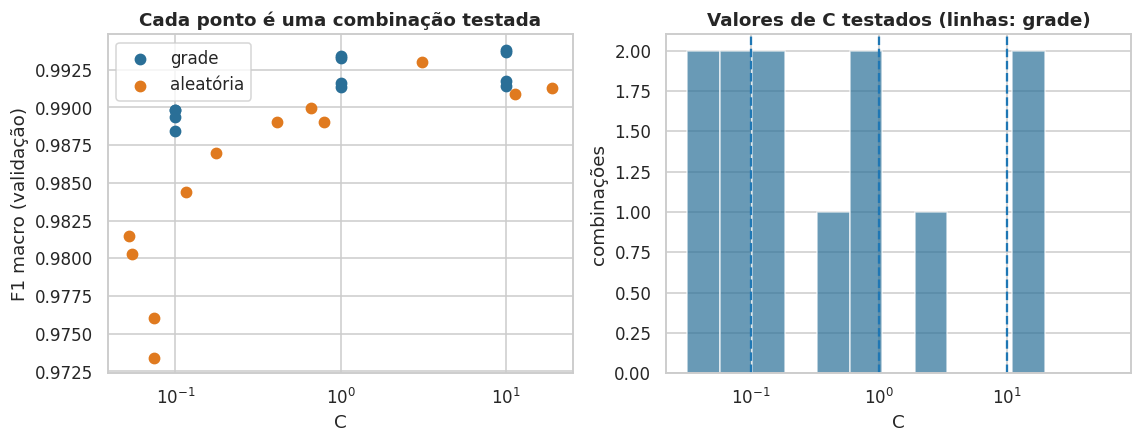

In [28]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(grid_results.param_linearsvc__C.astype(float), grid_results.mean_test_score, label="grade", s=45)
axes[0].scatter(random_same_budget.param_linearsvc__C.astype(float), random_same_budget.mean_test_score, label="aleatória", s=45)
axes[0].set(xscale="log", xlabel="C", ylabel="F1 macro (validação)", title="Cada ponto é uma combinação testada")
axes[0].legend()
grid_c_values = sorted(grid_results.param_linearsvc__C.astype(float).unique())
axes[1].hist(random_same_budget.param_linearsvc__C.astype(float), bins=np.logspace(-1.5, 1.8, 14), alpha=0.7, label="aleatória")
for value in grid_c_values:
    axes[1].axvline(value, color="tab:blue", linestyle="--")
axes[1].set(xscale="log", xlabel="C", ylabel="combinações", title="Valores de C testados (linhas: grade)")
plt.show()
save_figure(figure, "busca_grade_contra_aleatoria")

**Leitura.** Com o mesmo orçamento de 12 combinações, a **grade chegou a 0,9938** (pior combinação 0,9885) e a **busca aleatória a 0,9930** (pior 0,9734). Neste teste a grade **não perdeu**. A razão é o desenho dela: com 4 parâmetros e valores escolhidos olhando onde já se sabia que o F1 era alto, a grade é pequena e bem posicionada. O sorteio explorou um espaço maior (trigramas, `max_df`, `C` contínuo) e por isso trouxe tentativas ruins além das boas. A diferença entre os melhores (0,0008) é menor que o desvio entre dobras (cerca de 0,0014).

**Por que usar a busca aleatória mesmo assim.** A vantagem aparece quando o espaço cresce, e o da busca ampla abaixo (cinco famílias de classificador mais cinco parâmetros do TF-IDF) daria milhares de combinações por grade. Três razões práticas: o custo é o número de sorteios que escolhemos, não importa quantos parâmetros existam; cada sorteio testa um valor novo de **cada** parâmetro, enquanto a grade repete os mesmos valores; e parâmetros contínuos entram sem discretizar. Quando o espaço é pequeno e bem conhecido, como o desta comparação, a grade serve igual.

#### Busca aleatória ampla, com várias famílias

Agora o espaço de verdade: cinco famílias de classificador, cada uma com seus parâmetros, mais as escolhas do TF-IDF (tamanho do n-grama, frequência mínima e máxima de termos, escala sublinear, número máximo de termos). Sortear 40 combinações em um espaço desses seria impossível por grade.

In [29]:
from sklearn.pipeline import Pipeline

tfidf_choices = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)], "tfidf__min_df": [2, 3, 5], "tfidf__max_df": [0.5, 0.8, 0.9, 1.0],
    "tfidf__sublinear_tf": [True, False], "tfidf__max_features": [50_000, 100_000, 200_000],
}
classifier_families = [
    {"clf": [LinearSVC()], "clf__C": loguniform(0.05, 50)},
    {"clf": [LogisticRegression(max_iter=3000)], "clf__C": loguniform(1, 500)},
    {"clf": [SGDClassifier(max_iter=2000, random_state=RANDOM_STATE)], "clf__alpha": loguniform(1e-6, 1e-3),
     "clf__loss": ["hinge", "modified_huber", "log_loss"]},
    {"clf": [RidgeClassifier()], "clf__alpha": loguniform(0.05, 20)},
    {"clf": [ComplementNB()], "clf__alpha": loguniform(0.02, 1)},
]


@cached
def run_wide_random_search(texts, labels, groups, n_iter):
    search_space = [{**family, **tfidf_choices} for family in classifier_families]
    search = RandomizedSearchCV(Pipeline([("tfidf", TfidfVectorizer()), ("clf", LinearSVC())]), search_space,
                                n_iter=n_iter, cv=cross_validation, scoring="f1_macro", n_jobs=3, refit=False,
                                random_state=RANDOM_STATE)
    started = time.time()
    search.fit(texts, labels, groups=groups)
    results = pd.DataFrame(search.cv_results_)
    results["family"] = [type(params["clf"]).__name__ for params in results.params]
    results["parameters"] = [{k: v for k, v in params.items() if k != "clf"} for params in results.params]
    return results.drop(columns="params"), time.time() - started


WIDE_SEARCH_ITERATIONS = 40
wide_results, wide_seconds = run_wide_random_search(development.transcript, development.sector, development.group,
                                                   WIDE_SEARCH_ITERATIONS)
print(f"{len(wide_results)} combinações em {wide_seconds / 60:.1f} min")
best_per_family = (wide_results.sort_values("mean_test_score", ascending=False).groupby("family").head(1)
                   [["family", "mean_test_score", "std_test_score", "mean_fit_time", "parameters"]])
display(best_per_family.sort_values("mean_test_score", ascending=False).round(4).reset_index(drop=True))

40 combinações em 15.2 min


,family,mean_test_score,std_test_score,mean_fit_time,parameters
0,RidgeClassifier,0.9942,0.0016,18.2314,"{'clf__alpha': 0.3524801222067185, 'tfidf__max..."
1,LinearSVC,0.9938,0.0016,15.2489,"{'clf__C': 4.38571459368943, 'tfidf__max_df': ..."
2,SGDClassifier,0.9935,0.0020,15.7542,"{'clf__alpha': 1.7874463256238412e-05, 'clf__l..."
3,LogisticRegression,0.9920,0.0027,16.0373,"{'clf__C': 83.63671316748125, 'tfidf__max_df':..."
4,ComplementNB,0.9854,0.0021,2.5628,"{'clf__alpha': 0.19856496617407673, 'tfidf__ma..."


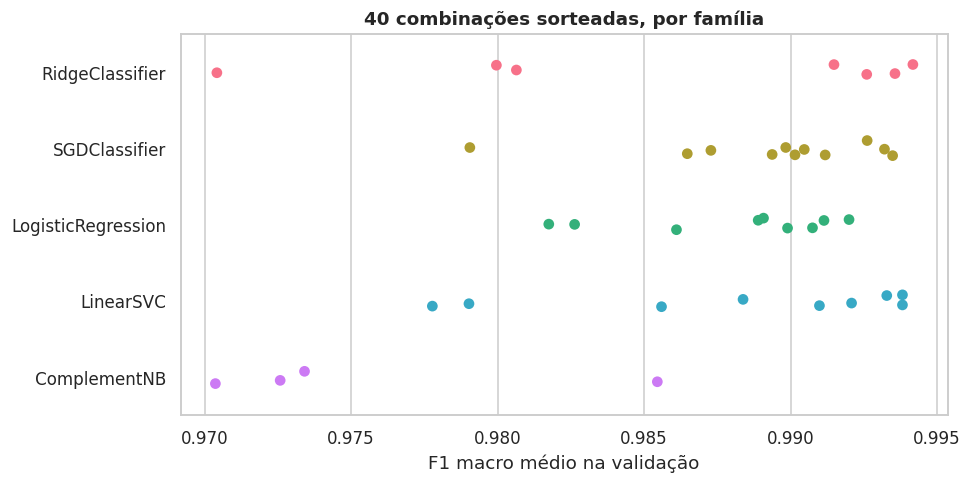

In [30]:
figure, axis = plt.subplots(figsize=(9, 4.5))
sns.stripplot(data=wide_results, x="mean_test_score", y="family", hue="family", legend=False, size=7, ax=axis)
axis.set(xlabel="F1 macro médio na validação", ylabel="", title=f"{len(wide_results)} combinações sorteadas, por família")
plt.show()
save_figure(figure, "busca_aleatoria_por_familia")

**Leitura.** Quarenta combinações em cerca de 15 minutos. Melhor de cada família: Ridge 0,9942 ± 0,0016, LinearSVC 0,9938 ± 0,0016, SGD 0,9935, regressão logística 0,9920 e Naive Bayes complementar 0,9854. As quatro primeiras estão a menos de um desvio entre dobras umas das outras: **empate técnico**. Os melhores usam trigramas (`ngram_range = (1, 3)`), mas o ganho sobre pares de palavras é pequeno e o custo de ajuste é maior. Pela regra fixada na seção 4.1 (empate vai para o mais simples e rápido), o **SVM linear calibrado** fica como referência do resto do caderno, e o melhor Ridge da busca entra como finalista na abertura do teste (4.13).

### 4.7 Outros atributos: os metadados ajudam o texto?

A seção 3 mostrou que só os metadados já separam bem acima do acaso. A pergunta agora é diferente: **somados** ao TF-IDF, eles melhoram o modelo de texto? Padronizamos as seis variáveis (média zero, desvio um, calculados no treino de cada dobra) e as juntamos às colunas do TF-IDF.

In [31]:
from scipy.sparse import csr_matrix, hstack
from sklearn.preprocessing import StandardScaler


def with_metadata(fold, weight):
    scaler = StandardScaler().fit(development[metadata_columns].iloc[fold["train_index"]])
    stack = lambda matrix, index: hstack([matrix, csr_matrix(weight * scaler.transform(development[metadata_columns].iloc[index]))]).tocsr()  # noqa: E731
    return {**fold, "X_train": stack(fold["X_train"], fold["train_index"]), "X_valid": stack(fold["X_valid"], fold["valid_index"])}


metadata_rows = []
for weight in [0.0, 0.05, 0.2, 1.0]:
    enriched_folds = [with_metadata(fold, weight) for fold in folds]
    scores = score_on_folds(lambda: LinearSVC(C=1.0), enriched_folds, development.sector)
    metadata_rows.append({"peso dos metadados": weight, "F1 validação": scores.valid_f1.mean(), "desvio": scores.valid_f1.std()})
display(pd.DataFrame(metadata_rows).round(4))

,peso dos metadados,F1 validação,desvio
0,0.00,0.9935,0.0017
1,0.05,0.9962,0.0013
2,0.20,0.9961,0.0011
3,1.00,0.9959,0.0012


**Leitura.** Somar os metadados ao texto melhora o F1 de validação de 0,9935 para 0,9962 (peso de 0,05; desvio entre dobras de 0,0013). É um ganho real, de cerca de 40% menos erros, e é exatamente o atalho da seção 3: confiança da transcrição e duração identificam o setor sem ler o texto. O ganho vem de uma propriedade da **origem** das transcrições e não do assunto. Se uma fonte nova de áudio mudar a faixa de confiança, esse modelo erra de um jeito que o texto sozinho não erraria. **Decisão:** o modelo de produção não usa metadados. O ganho fica registrado como opção a rever quando houver mais de uma fonte de áudio por setor, com dados para validar a robustez.

### 4.8 Modelos de linguagem pré-treinados

Os modelos acima veem o texto como um saco de palavras. Modelos como o BERT leem as palavras em contexto e já chegam treinados em bilhões de palavras. Testamos duas formas de usar um, com o mesmo critério de validação:

1. **Embeddings congelados.** O `all-MiniLM-L6-v2` (um modelo de frases derivado do BERT) transforma trechos de 180 palavras em vetores de 384 números; a chamada vira a média dos vetores dos seus trechos. Sobre isso treinamos uma regressão logística. O modelo pré-treinado não é alterado.
2. **Ajuste fino.** O `distilbert-base-uncased` (BERT reduzido, 66 milhões de parâmetros) é treinado de novo nas nossas chamadas, **1 época**, lendo só os **primeiros 128 tokens** (cerca de 100 palavras) de cada uma. Esse é um orçamento propositalmente pequeno: esta máquina não tem GPU, e uma tentativa de 2 épocas com 256 tokens passou de uma hora sem terminar e foi interrompida. O ajuste usa só a primeira dobra (treino e validação), e a função é guardada em disco. **O resultado mede o que cabe num orçamento de CPU, não o teto do BERT**: com GPU, janelas maiores e mais épocas o número tende a subir.

In [32]:
import os

os.environ.setdefault("HF_HOME", str(Path("../.cache/hf").resolve()))


@cached
def embed_with_minilm(transcripts, window_words=180):
    """Vetor de 384 números por chamada: média dos vetores de trechos de `window_words` palavras."""
    import torch
    from sentence_transformers import SentenceTransformer

    torch.set_num_threads(8)
    encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
    windows, owner = [], []
    for call_number, transcript in enumerate(transcripts):
        words = transcript.split() or [""]
        for start in range(0, len(words), window_words):
            windows.append(" ".join(words[start:start + window_words]))
            owner.append(call_number)
    window_vectors = encoder.encode(windows, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    sums = np.zeros((len(transcripts), window_vectors.shape[1]))
    np.add.at(sums, np.array(owner), window_vectors)
    return sums / np.bincount(owner)[:, None]


started = time.time()
call_embeddings = embed_with_minilm(calls.transcript.tolist())
print(f"{call_embeddings.shape[0]} chamadas, {call_embeddings.shape[1]} números cada ({time.time() - started:.0f} s nesta execução)")
development_embeddings, test_embeddings = call_embeddings[development_index], call_embeddings[test_index]

10121 chamadas, 384 números cada (0 s nesta execução)


In [33]:
embedding_folds = [{**fold, "X_train": development_embeddings[fold["train_index"]], "X_valid": development_embeddings[fold["valid_index"]]}
                   for fold in folds]
embedding_scores = score_on_folds(lambda: LogisticRegression(C=10.0, max_iter=3000), embedding_folds, development.sector)
print(f"MiniLM congelado + regressão logística: validação {embedding_scores.valid_f1.mean():.4f} ± {embedding_scores.valid_f1.std():.4f}"
      f" | treino {embedding_scores.train_f1.mean():.4f}")

MiniLM congelado + regressão logística: validação 0.9720 ± 0.0038 | treino 0.9838


In [34]:
@cached
def finetune_distilbert(train_texts, train_labels, valid_texts, test_texts, epochs=1, max_length=128, batch_size=16, learning_rate=5e-5):
    """Ajuste fino do DistilBERT. Devolve as probabilidades da validação e do teste (estas só são lidas na seção 4.13)."""
    import torch
    from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

    torch.manual_seed(RANDOM_STATE)
    torch.set_num_threads(12)
    model_name = "distilbert-base-uncased"
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=len(SECTORS))
    label_number = {sector: number for number, sector in enumerate(SECTORS)}
    labels = torch.tensor([label_number[label] for label in train_labels])

    def encode(texts):
        return tokenizer(list(texts), truncation=True, max_length=max_length, padding=True, return_tensors="pt")

    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.01)
    steps = epochs * int(np.ceil(len(train_texts) / batch_size))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.06 * steps), steps)
    order_generator = np.random.default_rng(RANDOM_STATE)
    started = time.time()
    epoch_losses = []
    model.train()
    for _ in range(epochs):
        order = order_generator.permutation(len(train_texts))
        losses = []
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            output = model(**encode([train_texts[i] for i in batch]), labels=labels[batch])
            output.loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
            losses.append(float(output.loss))
        epoch_losses.append(float(np.mean(losses)))

    def predict_probabilities(texts):
        model.eval()
        parts = []
        with torch.no_grad():
            for start in range(0, len(texts), 32):
                logits = model(**encode(texts[start:start + 32])).logits
                parts.append(torch.softmax(logits, dim=1).numpy())
        return np.vstack(parts)

    return {"valid_probabilities": predict_probabilities(valid_texts), "test_probabilities": predict_probabilities(test_texts),
            "epoch_losses": epoch_losses, "training_seconds": time.time() - started}


started = time.time()
bert_run = finetune_distilbert(
    development.transcript.iloc[first_fold["train_index"]].tolist(), development.sector.iloc[first_fold["train_index"]].tolist(),
    development.transcript.iloc[first_fold["valid_index"]].tolist(), test.transcript.tolist())
bert_valid_prediction = np.array(SECTORS)[bert_run["valid_probabilities"].argmax(axis=1)]
bert_valid_f1 = f1_score(development.sector.iloc[first_fold["valid_index"]], bert_valid_prediction, average="macro")
print(f"DistilBERT ajustado: F1 macro na validação da primeira dobra {bert_valid_f1:.4f}; "
      f"perda por época {np.round(bert_run['epoch_losses'], 3)}; ajuste de {bert_run['training_seconds'] / 60:.0f} min "
      f"({time.time() - started:.0f} s nesta execução)")
svm_first_fold = score_on_folds(lambda: LinearSVC(C=1.0), folds[:1], development.sector)
print(f"Mesma dobra, SVM linear com TF-IDF: {svm_first_fold.valid_f1.iloc[0]:.4f}")

DistilBERT ajustado: F1 macro na validação da primeira dobra 0.9475; perda por época [0.265]; ajuste de 31 min (0 s nesta execução)


Mesma dobra, SVM linear com TF-IDF: 0.9908


**Leitura.** O MiniLM congelado com regressão logística tem F1 de 0,9720 ± 0,0038 na validação cruzada. O DistilBERT ajustado (1 época, 128 tokens, 31 minutos de CPU) tem 0,9475 na primeira dobra, contra 0,9908 do SVM com TF-IDF na mesma dobra. Os dois ficam abaixo do TF-IDF. A explicação mais provável: o sinal do setor está em palavras específicas (`boarding`, `windshield`, `vin`) que o TF-IDF já captura com a chamada inteira, enquanto o modelo de linguagem, com janela curta e orçamento pequeno, só vê o começo da chamada, que é o trecho mais genérico. Isso responde à pergunta "por que não BERT": foi testado e, **neste orçamento**, perde. Não prova que um BERT com GPU, janela maior (por exemplo, a chamada em trechos) e mais épocas perderia.

### 4.9 Um detector por setor

Uma ideia natural: em vez de um modelo que escolhe entre três setores, treinar **três modelos binários** ("é automotivo?", "é home service?", "é medicare?") e seguir o setor cujo detector disser sim. A vantagem é poder reconhecer o caso de nenhum detector dizer sim ou de mais de um dizer sim, que seria uma chamada ambígua.

Vale saber que o `LinearSVC` do scikit-learn já funciona assim por dentro (estratégia um-contra-todos), então o resultado de escolher o maior dos três escores é o mesmo do modelo multiclasse. O que ganhamos é medir **quantas chamadas têm exatamente um detector positivo**.

In [35]:
detector_scores = np.zeros((len(development), len(SECTORS)))
for fold in folds:
    for sector_number, sector in enumerate(SECTORS):
        detector = LinearSVC(C=1.0).fit(fold["X_train"], development.sector.iloc[fold["train_index"]] == sector)
        detector_scores[fold["valid_index"], sector_number] = detector.decision_function(fold["X_valid"])

positives = (detector_scores > 0).sum(axis=1)
by_argmax = np.array(SECTORS)[detector_scores.argmax(axis=1)]
correct = by_argmax == development.sector.to_numpy()
detector_table = pd.DataFrame({
    "detectores positivos": ["nenhum", "exatamente um", "dois ou mais"],
    "chamadas": [(positives == 0).sum(), (positives == 1).sum(), (positives >= 2).sum()],
    "acerto do maior escore": [correct[positives == 0].mean(), correct[positives == 1].mean(),
                               correct[positives >= 2].mean() if (positives >= 2).any() else np.nan],
})
print(f"F1 macro escolhendo o maior escore: {f1_score(development.sector, by_argmax, average='macro'):.4f}")
display(detector_table.round(4))

F1 macro escolhendo o maior escore: 0.9935


,detectores positivos,chamadas,acerto do maior escore
0,nenhum,116,0.7845
1,exatamente um,7976,0.9967
2,dois ou mais,2,0.5000


**Leitura.** O F1 escolhendo o maior escore (0,9935) é igual ao do modelo multiclasse, como esperado. Em 7.976 de 8.094 chamadas exatamente um detector diz sim, e nessas o acerto é 0,9967. Em 116 chamadas **nenhum** detector é positivo (acerto do maior escore: 0,7845) e em 2 dois são positivos. Dito de outra forma, "nenhum ou mais de um detector positivo" é um bom sinal de dúvida: essas 118 chamadas (1,5% do total) concentram cerca de metade dos erros. Esse sinal vale como alternativa ao limiar de probabilidade da seção 4.14.

### 4.10 Combinar modelos

Uma combinação (ensemble) faz vários modelos votarem. Funciona quando os modelos erram em chamadas **diferentes**. Reunimos as probabilidades de validação de quatro modelos, cada uma calculada por um modelo que não viu a chamada: regressão logística, SVM linear calibrado, Naive Bayes complementar (as três sobre TF-IDF) e regressão logística sobre os embeddings do MiniLM.

O SVM não produz probabilidade por conta própria; o `CalibratedClassifierCV` ajusta uma curva que transforma o escore em probabilidade.

In [36]:
from sklearn.calibration import CalibratedClassifierCV

member_factories = {
    "regressão logística": lambda: LogisticRegression(C=5.0, max_iter=3000),
    "SVM linear calibrado": lambda: CalibratedClassifierCV(LinearSVC(C=1.0), cv=3, method="sigmoid"),
    "Naive Bayes complementar": lambda: ComplementNB(alpha=0.3),
}
out_of_fold_probabilities = {name: np.zeros((len(development), len(SECTORS))) for name in [*member_factories, "MiniLM + regressão logística"]}
for fold, embedding_fold in zip(folds, embedding_folds):
    labels_train = development.sector.iloc[fold["train_index"]]
    for name, make_model in member_factories.items():
        out_of_fold_probabilities[name][fold["valid_index"]] = make_model().fit(fold["X_train"], labels_train).predict_proba(fold["X_valid"])
    minilm = LogisticRegression(C=10.0, max_iter=3000).fit(embedding_fold["X_train"], labels_train)
    out_of_fold_probabilities["MiniLM + regressão logística"][fold["valid_index"]] = minilm.predict_proba(embedding_fold["X_valid"])


def macro_f1_of(probabilities):
    return f1_score(development.sector, np.array(SECTORS)[probabilities.argmax(axis=1)], average="macro")


member_table = pd.DataFrame({"F1 macro (validação cruzada)": {name: macro_f1_of(p) for name, p in out_of_fold_probabilities.items()}})
member_table["chamadas erradas"] = [int((np.array(SECTORS)[p.argmax(axis=1)] != development.sector.to_numpy()).sum())
                                    for p in out_of_fold_probabilities.values()]
display(member_table.round(4))

,F1 macro (validação cruzada),chamadas erradas
regressão logística,0.9909,72
SVM linear calibrado,0.9928,58
Naive Bayes complementar,0.9835,130
MiniLM + regressão logística,0.9720,227


In [37]:
member_names = list(out_of_fold_probabilities)
member_wrong = {name: np.array(SECTORS)[p.argmax(axis=1)] != development.sector.to_numpy() for name, p in out_of_fold_probabilities.items()}
overlap = pd.DataFrame([[ (member_wrong[a] & member_wrong[b]).sum() for b in member_names] for a in member_names],
                       index=member_names, columns=member_names)
print("Chamadas que dois modelos erram ao mesmo tempo (a diagonal é o total de erros de cada um):")
display(overlap)

equal_weights = np.ones(len(member_names)) / len(member_names)
mix = lambda weights: sum(w * out_of_fold_probabilities[name] for w, name in zip(weights, member_names))  # noqa: E731
weight_generator = np.random.default_rng(RANDOM_STATE)
candidate_weights = weight_generator.dirichlet(np.ones(len(member_names)), size=400)
weight_scores = np.array([macro_f1_of(mix(weights)) for weights in candidate_weights])
best_weights = candidate_weights[weight_scores.argmax()]
print(f"pesos iguais: {macro_f1_of(mix(equal_weights)):.4f}")
print(f"melhor entre 400 sorteios de pesos: {weight_scores.max():.4f} com pesos {dict(zip(member_names, best_weights.round(2)))}")
print(f"mediana dos 400 sorteios: {np.median(weight_scores):.4f} (o melhor sorteio escolhido a dedo sempre parece bom)")

Chamadas que dois modelos erram ao mesmo tempo (a diagonal é o total de erros de cada um):


,regressão logística,SVM linear calibrado,Naive Bayes complementar,MiniLM + regressão logística
regressão logística,72,57,58,41
SVM linear calibrado,57,58,49,39
Naive Bayes complementar,58,49,130,64
MiniLM + regressão logística,41,39,64,227


pesos iguais: 0.9913
melhor entre 400 sorteios de pesos: 0.9929 com pesos {'regressão logística': np.float64(0.0), 'SVM linear calibrado': np.float64(0.89), 'Naive Bayes complementar': np.float64(0.01), 'MiniLM + regressão logística': np.float64(0.1)}
mediana dos 400 sorteios: 0.9904 (o melhor sorteio escolhido a dedo sempre parece bom)


**Leitura.** Os modelos erram nas mesmas chamadas: o SVM e a regressão logística têm 57 erros em comum (de 58 e 72). Por isso combinar não ajuda. Com pesos iguais o F1 é 0,9913, abaixo do 0,9928 do SVM sozinho; o melhor de 400 sorteios de pesos (0,9929) dá 89% do peso ao SVM e apenas o iguala, e a mediana dos sorteios é 0,9904. Voto só funciona quando os votantes erram em lugares diferentes, e aqui não erram.

### 4.11 Onde o modelo erra

Tomamos como referência o **SVM linear calibrado**: entre os modelos que empatam dentro do desvio entre dobras (seção 4.4 e a busca da seção 4.6), é o mais simples, o mais rápido de ajustar e o que permite ler os termos que pesaram na decisão. Os erros abaixo são os da validação cruzada, ou seja, cada chamada foi prevista por um modelo que não a viu.

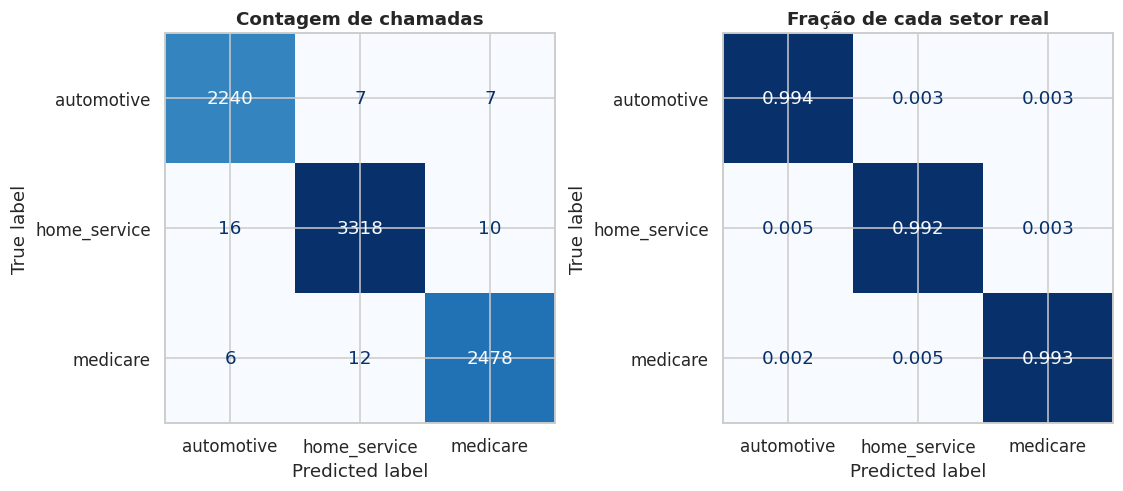

              precision    recall  f1-score   support

  automotive     0.9903    0.9938    0.9920      2254
home_service     0.9943    0.9922    0.9933      3344
    medicare     0.9932    0.9928    0.9930      2496

    accuracy                         0.9928      8094
   macro avg     0.9926    0.9929    0.9928      8094
weighted avg     0.9928    0.9928    0.9928      8094



In [38]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

reference_probabilities = out_of_fold_probabilities["SVM linear calibrado"]
reference_prediction = np.array(SECTORS)[reference_probabilities.argmax(axis=1)]
development_with_prediction = development.assign(predicted=reference_prediction, confidence_of_model=reference_probabilities.max(axis=1))
development_with_prediction["wrong"] = development_with_prediction.predicted != development_with_prediction.sector

figure, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ConfusionMatrixDisplay.from_predictions(development.sector, reference_prediction, labels=SECTORS, cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Contagem de chamadas")
ConfusionMatrixDisplay.from_predictions(development.sector, reference_prediction, labels=SECTORS, normalize="true",
                                        values_format=".3f", cmap="Blues", colorbar=False, ax=axes[1])
axes[1].set_title("Fração de cada setor real")
plt.show()
save_figure(figure, "matriz_de_confusao")
print(classification_report(development.sector, reference_prediction, digits=4))

In [39]:
errors = development_with_prediction[development_with_prediction.wrong]
pair_counts = errors.groupby(["sector", "predicted"]).size().rename("chamadas").reset_index()
pair_counts["par"] = pair_counts.sector + " previsto como " + pair_counts.predicted
display(pair_counts.sort_values("chamadas", ascending=False)[["par", "chamadas"]].reset_index(drop=True))

length_bucket = pd.qcut(development_with_prediction.word_count, 5)
display(development_with_prediction.groupby(length_bucket).wrong.agg(["size", "sum", "mean"])
        .rename(columns={"size": "chamadas", "sum": "erros", "mean": "taxa de erro"}).round(4))

greeting = development_with_prediction.transcript.str.lower().str.startswith(("thank you for calling", "thanks for calling"))
display(development_with_prediction.groupby(greeting.rename("abre com agradecimento")).wrong.agg(["size", "sum", "mean"]).round(4))

confidence_bucket = pd.qcut(development_with_prediction.asr_confidence, 5)
display(development_with_prediction.groupby(confidence_bucket).wrong.agg(["size", "sum", "mean"]).round(4))

,par,chamadas
0,home_service previsto como automotive,16
1,medicare previsto como home_service,12
2,home_service previsto como medicare,10
3,automotive previsto como home_service,7
4,automotive previsto como medicare,7
5,medicare previsto como automotive,6


,chamadas,erros,taxa de erro
word_count,,,
"(30.999, 351.0]",1622,23,0.0142
"(351.0, 483.0]",1620,12,0.0074
"(483.0, 643.0]",1619,9,0.0056
"(643.0, 947.0]",1616,9,0.0056
"(947.0, 8517.0]",1617,5,0.0031


,size,sum,mean
abre com agradecimento,,,
False,4732,42,0.0089
True,3362,16,0.0048


,size,sum,mean
asr_confidence,,,
"(0.566, 0.871]",1619,22,0.0136
"(0.871, 0.888]",1619,9,0.0056
"(0.888, 0.906]",1618,12,0.0074
"(0.906, 0.945]",1619,6,0.0037
"(0.945, 0.993]",1619,9,0.0056


In [40]:
print("Seis erros, com o começo do texto:")
for _, row in errors.sample(6, random_state=RANDOM_STATE).iterrows():
    print(f"- real: {row.sector} | previsto: {row.predicted} (confiança do modelo {row.confidence_of_model:.2f}) | {row.word_count} palavras")
    print("  ", row.transcript[:330].replace("\n", " "))

(saída omitida: trechos de transcrições de terceiros não são publicados)


**Leitura.**
- São 58 erros em 8.094 chamadas (0,72%). O par mais comum é home service previsto como automotivo (16).
- O **automotivo não é o setor mais fácil**: ele tem a transcrição mais confiável e as chamadas mais longas, mas o menor F1 por setor (0,9920, contra 0,9933 e 0,9930), por pouco.
- O erro cai com o tamanho da chamada: 1,42% no quinto mais curto (até 351 palavras) e 0,31% no mais longo. E cresce com a qualidade ruim da transcrição: 1,36% no quinto de menor confiança, contra 0,37% a 0,74% nos demais.
- A hipótese de que chamadas que abrem com o agradecimento padrão errariam mais **não se confirmou**: elas erram menos (0,48% contra 0,89%).
- Nos exemplos lidos aparecem chamadas de transferência e de pedido de outra pessoa ou de garantia, sem assunto próprio do setor.

### 4.12 O que pesa na decisão e quantas palavras o modelo precisa

**Termos que pesam.** No SVM linear cada termo tem um peso por setor; o gráfico mostra os 12 termos de maior peso positivo em cada setor.

**Quantas palavras bastam.** Treinamos e validamos o mesmo modelo com apenas as primeiras N palavras de cada chamada. Isso mede o quanto de chamada é preciso ouvir para decidir o setor, e tem uso prático: classificar **durante** a ligação, para encaminhar o atendimento ou preparar a tela do atendente, sem esperar a transcrição inteira.

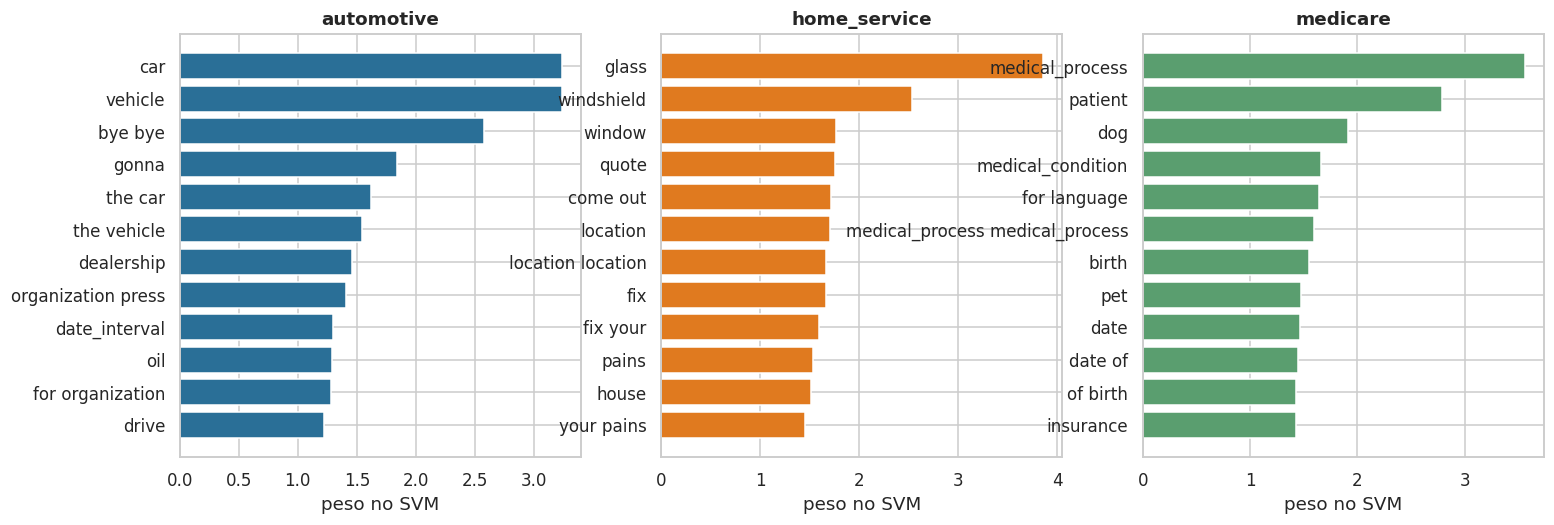

In [41]:
full_vectorizer = TfidfVectorizer(**TFIDF_SETTINGS)
full_matrix = full_vectorizer.fit_transform(development.transcript)
full_svm = LinearSVC(C=1.0).fit(full_matrix, development.sector)
vocabulary_terms = np.array(full_vectorizer.get_feature_names_out())

figure, axes = plt.subplots(1, 3, figsize=(16, 5))
heaviest_terms = {}
for axis, (sector_number, sector) in zip(axes, enumerate(full_svm.classes_)):
    top = full_svm.coef_[sector_number].argsort()[::-1][:12]
    heaviest_terms[sector] = vocabulary_terms[top].tolist()
    axis.barh(vocabulary_terms[top][::-1], full_svm.coef_[sector_number][top][::-1], color=SECTOR_COLORS[sector])
    axis.set(title=sector, xlabel="peso no SVM")
plt.show()
save_figure(figure, "termos_que_pesam")

,palavras lidas,F1 macro,desvio
0,20,0.8607,0.0068
1,40,0.9315,0.0033
2,80,0.9632,0.0063
3,160,0.9819,0.0030
4,320,0.9902,0.0025
5,640,0.9926,0.0010
6,todas,0.9935,0.0015


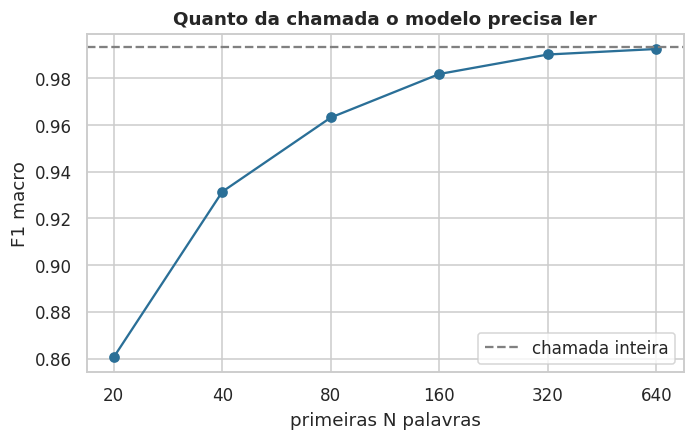

In [42]:
word_limits = [20, 40, 80, 160, 320, 640]
truncation_rows = []
for limit in word_limits:
    first_words = development.transcript.str.split().str[:limit].str.join(" ")
    mean, std = cross_validated_f1(reference_model(), first_words)
    truncation_rows.append({"palavras lidas": limit, "F1 macro": mean, "desvio": std})
truncation_rows.append({"palavras lidas": "todas", "F1 macro": reference_mean, "desvio": reference_std})
truncation_table = pd.DataFrame(truncation_rows)
display(truncation_table.round(4))

figure, axis = plt.subplots(figsize=(7, 4))
axis.plot(range(len(word_limits)), truncation_table["F1 macro"][:len(word_limits)], marker="o")
axis.axhline(reference_mean, color="gray", linestyle="--", label="chamada inteira")
axis.set(xticks=range(len(word_limits)), xticklabels=word_limits, xlabel="primeiras N palavras", ylabel="F1 macro",
         title="Quanto da chamada o modelo precisa ler")
axis.legend()
plt.show()
save_figure(figure, "palavras_necessarias")

**Leitura.** Com as primeiras 20 palavras o F1 é 0,8607; com 40, 0,9315; com 80, 0,9632; com 160, 0,9819; com 320, 0,9902; com 640, 0,9926 (chamada inteira: 0,9935). Na prática, classificar durante a ligação, com cerca de 160 palavras (uma fração da chamada), já dá 0,98. Isso tem uso: encaminhar o atendimento ou preparar a tela do atendente sem esperar a transcrição inteira. O custo de decidir cedo é um erro maior, e a probabilidade devolvida deve guiar quando esperar mais.

### 4.13 Conjunto de teste: a abertura única

Até aqui nada olhou as chamadas de teste. Os candidatos finais, todos ajustados com o desenvolvimento inteiro:

| Candidato | De onde vem |
|---|---|
| Regressão logística (C=5) | ponto de comparação (4.2) |
| SVM linear calibrado (C=1) | referência da análise de erros (4.11) |
| Melhor da busca aleatória | a combinação de maior F1 médio na seção 4.6 |
| Combinação dos quatro modelos | pesos iguais (seção 4.10); não usamos os pesos sorteados, que já nasceram otimizados nos mesmos dados |
| MiniLM congelado + regressão logística | modelo pré-treinado, sem ajuste fino (4.8) |
| DistilBERT com ajuste fino | modelo pré-treinado com ajuste fino (4.8), treinado só na primeira dobra |

As medidas: F1 macro, número de chamadas erradas, **ECE** (erro de calibração: quando o modelo diz 90% de confiança, em quantos por cento das vezes acerta?) e perda logarítmica (penaliza confiança errada). A comparação entre pares usa o teste de McNemar, que olha só as chamadas em que os dois modelos discordam e pergunta se um ganha mais do que o acaso explicaria.

In [43]:
from scipy.stats import binomtest
from sklearn.metrics import accuracy_score, log_loss

CLASSIFIER_CLASSES = {"LinearSVC": LinearSVC, "LogisticRegression": lambda **p: LogisticRegression(max_iter=3000, **p),
                      "SGDClassifier": lambda **p: SGDClassifier(max_iter=2000, random_state=RANDOM_STATE, **p),
                      "RidgeClassifier": RidgeClassifier, "ComplementNB": ComplementNB}


def pipeline_from_search_row(row):
    tfidf_settings = {name.split("__", 1)[1]: value for name, value in row.parameters.items() if name.startswith("tfidf__")}
    classifier_settings = {name.split("__", 1)[1]: value for name, value in row.parameters.items() if name.startswith("clf__")}
    classifier = CLASSIFIER_CLASSES[row.family](**classifier_settings)
    if not hasattr(classifier, "predict_proba"):
        classifier = CalibratedClassifierCV(classifier, cv=3, method="sigmoid")
    return make_pipeline(TfidfVectorizer(**tfidf_settings), classifier)


def expected_calibration_error(probabilities, truth, bins=10):
    confidence = probabilities.max(axis=1)
    hit = (np.array(SECTORS)[probabilities.argmax(axis=1)] == truth).astype(float)
    bin_of = np.clip((confidence * bins).astype(int), 0, bins - 1)
    return float(sum((bin_of == b).mean() * abs(confidence[bin_of == b].mean() - hit[bin_of == b].mean()) for b in range(bins) if (bin_of == b).any()))


best_search_row = wide_results.sort_values("mean_test_score", ascending=False).iloc[0]
print("Melhor da busca aleatória:", best_search_row.family, {k: v for k, v in best_search_row.parameters.items()})

test_probabilities = {}
tfidf_for_test = TfidfVectorizer(**TFIDF_SETTINGS)
matrix_development = tfidf_for_test.fit_transform(development.transcript)
matrix_test = tfidf_for_test.transform(test.transcript)
for name, make_model in member_factories.items():
    test_probabilities[name] = make_model().fit(matrix_development, development.sector).predict_proba(matrix_test)
test_probabilities["MiniLM + regressão logística"] = (LogisticRegression(C=10.0, max_iter=3000)
                                                      .fit(development_embeddings, development.sector).predict_proba(test_embeddings))
test_probabilities["melhor da busca aleatória"] = pipeline_from_search_row(best_search_row).fit(development.transcript, development.sector).predict_proba(test.transcript)
test_probabilities["combinação (pesos iguais)"] = sum(test_probabilities[name] for name in member_names) / len(member_names)
test_probabilities["DistilBERT com ajuste fino"] = bert_run["test_probabilities"]

test_truth = test.sector.to_numpy()
test_prediction = {name: np.array(SECTORS)[p.argmax(axis=1)] for name, p in test_probabilities.items()}
test_table = pd.DataFrame([{
    "modelo": name, "F1 macro": f1_score(test_truth, test_prediction[name], average="macro"),
    "erros": int((test_prediction[name] != test_truth).sum()), "acurácia": accuracy_score(test_truth, test_prediction[name]),
    "ECE": expected_calibration_error(p, test_truth), "perda logarítmica": log_loss(test_truth, p, labels=SECTORS),
} for name, p in test_probabilities.items()]).sort_values("F1 macro", ascending=False).reset_index(drop=True)
print(f"{len(test)} chamadas de teste")
display(test_table.round(4))

Melhor da busca aleatória: RidgeClassifier {'clf__alpha': np.float64(0.3524801222067185), 'tfidf__max_df': 1.0, 'tfidf__max_features': 200000, 'tfidf__min_df': 3, 'tfidf__ngram_range': (1, 3), 'tfidf__sublinear_tf': True}


2027 chamadas de teste


,modelo,F1 macro,erros,acurácia,ECE,perda logarítmica
0,melhor da busca aleatória,0.9931,14,0.9931,0.0077,0.0300
1,SVM linear calibrado,0.9921,16,0.9921,0.0065,0.0331
2,regressão logística,0.9915,17,0.9916,0.0501,0.0772
3,combinação (pesos iguais),0.9915,17,0.9916,0.0329,0.0586
4,Naive Bayes complementar,0.9842,31,0.9847,0.0285,0.0748
5,MiniLM + regressão logística,0.9766,47,0.9768,0.0154,0.0802
6,DistilBERT com ajuste fino,0.9643,68,0.9665,0.0118,0.1099


In [44]:
def mcnemar(truth, prediction_a, prediction_b):
    only_a_wrong = int(((prediction_a != truth) & (prediction_b == truth)).sum())
    only_b_wrong = int(((prediction_b != truth) & (prediction_a == truth)).sum())
    discordant = only_a_wrong + only_b_wrong
    p_value = binomtest(min(only_a_wrong, only_b_wrong), discordant, 0.5).pvalue if discordant else 1.0
    return only_a_wrong, only_b_wrong, p_value


reference_name = "SVM linear calibrado"
mcnemar_rows = []
for name in test_prediction:
    if name == reference_name:
        continue
    only_reference_wrong, only_other_wrong, p_value = mcnemar(test_truth, test_prediction[reference_name], test_prediction[name])
    mcnemar_rows.append({"comparado com SVM linear calibrado": name, "só o SVM erra": only_reference_wrong,
                         "só o outro erra": only_other_wrong, "p (McNemar)": p_value})
display(pd.DataFrame(mcnemar_rows).round(4))

bootstrap_generator = np.random.default_rng(RANDOM_STATE)
bootstrap_f1 = []
for _ in range(1000):
    resample = bootstrap_generator.integers(0, len(test), len(test))
    bootstrap_f1.append(f1_score(test_truth[resample], test_prediction[reference_name][resample], average="macro"))
interval = np.percentile(bootstrap_f1, [2.5, 97.5])
print(f"SVM linear calibrado: F1 macro {test_table.set_index('modelo').loc[reference_name, 'F1 macro']:.4f}, intervalo de 95% por reamostragem: {interval[0]:.4f} a {interval[1]:.4f}")

,comparado com SVM linear calibrado,só o SVM erra,só o outro erra,p (McNemar)
0,regressão logística,0,1,1.0000
1,Naive Bayes complementar,2,17,0.0007
2,MiniLM + regressão logística,5,36,0.0000
3,melhor da busca aleatória,2,0,0.5000
4,combinação (pesos iguais),2,3,1.0000
5,DistilBERT com ajuste fino,7,59,0.0000


SVM linear calibrado: F1 macro 0.9921, intervalo de 95% por reamostragem: 0.9883 a 0.9956


**Leitura.** No teste de 2.027 chamadas: melhor da busca (Ridge) 0,9931 com 14 erros; SVM linear calibrado 0,9921 com 16; regressão logística 0,9915 com 17; combinação 0,9915 com 17; Naive Bayes complementar 0,9842 com 31; MiniLM 0,9766 com 47; DistilBERT 0,9643 com 68. Contra o SVM, o McNemar dá empate com o Ridge (só o SVM erra em 2, só o Ridge em 0, p = 0,50), com a regressão logística (0 e 1, p = 1,0) e com a combinação (2 e 3, p = 1,0). Naive Bayes, MiniLM e DistilBERT são piores com p < 0,001. O intervalo de 95% do SVM (0,9883 a 0,9956) cobre os empatados.

**Decisão:** fica o **SVM linear calibrado**. Empata com o melhor, é simples e rápido, tem a probabilidade mais bem calibrada entre os finalistas (ECE de 0,0065) e permite ler os termos que pesaram. Estes números são do conjunto de teste deste caderno (divisão estratificada por grupo). O pipeline de produção usa uma divisão por hash do texto, que não muda quando o conjunto cresce, então seu teste tem outras chamadas e seus números não se comparam chamada a chamada com os daqui.

### 4.14 Aviso de baixa confiança

Mesmo um modelo de 99% erra. O que faz diferença na operação é **saber quais respostas desconfiar**. A API marca como "baixa confiança" a chamada cuja maior probabilidade fica abaixo de um limiar. A pergunta é onde pôr o limiar.

Escolhemos com as probabilidades de validação cruzada do desenvolvimento (nunca com o teste) e com uma regra de orçamento: **marcar no máximo 6% das chamadas**, porque um aviso que dispara em muita chamada deixa de ser lido. Entre os limiares que cabem no orçamento, vence o que captura mais erros. Depois conferimos no teste.

In [45]:
reference_correct = reference_prediction == development.sector.to_numpy()
threshold_rows = []
for threshold in [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 0.98]:
    flagged = reference_probabilities.max(axis=1) < threshold
    threshold_rows.append({"limiar": threshold, "chamadas marcadas": flagged.mean(),
                           "erros capturados": (flagged & ~reference_correct).sum() / max((~reference_correct).sum(), 1),
                           "precisão do aviso": (flagged & ~reference_correct).sum() / max(flagged.sum(), 1)})
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(3))

FLAG_BUDGET = 0.06
within_budget = threshold_table[threshold_table["chamadas marcadas"] <= FLAG_BUDGET]
chosen_threshold = float(within_budget.sort_values("erros capturados").iloc[-1]["limiar"])
test_confidence = test_probabilities[reference_name].max(axis=1)
test_flagged = test_confidence < chosen_threshold
test_wrong = test_prediction[reference_name] != test_truth
print(f"limiar escolhido: {chosen_threshold}")
print(f"no teste: {test_flagged.mean():.1%} das chamadas marcadas, {(test_flagged & test_wrong).sum()} de {test_wrong.sum()} erros capturados")

,limiar,chamadas marcadas,erros capturados,precisão do aviso
0,0.50,0.000,0.017,0.500
1,0.60,0.004,0.293,0.472
2,0.70,0.011,0.414,0.267
3,0.80,0.018,0.586,0.230
4,0.85,0.028,0.724,0.187
5,0.90,0.041,0.828,0.144
6,0.95,0.065,0.914,0.101
7,0.98,0.122,0.931,0.055


limiar escolhido: 0.9
no teste: 3.7% das chamadas marcadas, 12 de 16 erros capturados


**Leitura.** O limiar de 0,90 é o maior que cabe no orçamento: marca 4,1% das chamadas de desenvolvimento e captura 82,8% dos erros. A precisão do aviso é de 14,4%, ou seja, a cada sete avisos, um é erro de fato: o aviso serve para mandar a chamada para conferência, não para trocá-la. No teste marcou 3,7% das chamadas e capturou 12 dos 16 erros.

## 5. Subgrupos dentro de cada setor

Aqui não há rótulo. A pergunta é se, dentro de cada setor, existem tipos de chamada que se repetem, e se esses tipos se sustentam quando mudamos de dados, de algoritmo ou de representação.

A exploração do vocabulário (seção 2.4) já indicou o caminho: o medicare mistura saúde de pessoas e de animais, o home service mistura vidro, fauna e pesquisa de satisfação. Se isso for verdade, um agrupamento deve reencontrar essas divisões sem que ninguém diga onde elas estão.

**O que fazemos, em ordem**
1. Representar cada chamada como um vetor (TF-IDF reduzido a 100 dimensões e normalizado).
2. Escolher quantos grupos (k) com três evidências: separação (silhueta), estabilidade e tamanho do menor grupo.
3. Comparar algoritmos: KMeans, hierárquico (Ward), mistura de gaussianas, DBSCAN e fatoração em tópicos (NMF).
4. Olhar o mapa em duas dimensões (UMAP) e os vizinhos mais próximos de cada chamada.
5. Repetir com embeddings de frase (MiniLM) para ver se uma representação mais "semântica" muda o desenho.
6. Ler os grupos, validar com temas que não foram usados para nomear e dar nome.

**Regra de honestidade.** Sem rótulo não existe "acerto". Medimos **estabilidade** (os mesmos grupos reaparecem com outra amostra?) e **concordância com temas independentes**. Um grupo instável não é um grupo.

### 5.1 Representação e ferramentas

O TF-IDF desta etapa é diferente do usado para o setor: ignora palavras comuns do inglês (`stop_words`), descarta termos presentes em mais de 40% das chamadas do setor e reduz tudo a 100 dimensões com SVD. Essas escolhas existem para que o agrupamento olhe o **assunto** da chamada e não a cortesia. Os marcadores de dado pessoal viram termos próprios (`tagpersonname`) porque dizem algo sobre a chamada (por exemplo, `tagmedicalcondition` aparece em consulta médica).

In [46]:
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import NMF
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors


def mark_pii_tags(text):
    return PII_TAG.sub(lambda match: " tag" + match.group(1).lower().replace("_", "") + " ", text)


class SectorSpace:
    """Representação das chamadas de um setor: matriz TF-IDF e vetores unitários de 100 dimensões."""

    def __init__(self, sector):
        self.sector = sector
        self.dev_calls = development[development.sector == sector].reset_index(drop=True)
        self.test_calls = test[test.sector == sector].reset_index(drop=True)
        self.vectorizer = TfidfVectorizer(min_df=5, max_df=0.4, sublinear_tf=True, ngram_range=(1, 2),
                                          stop_words="english", max_features=100_000)
        self.tfidf = self.vectorizer.fit_transform(self.dev_calls.transcript.map(mark_pii_tags))
        self.reducer = TruncatedSVD(100, random_state=RANDOM_STATE).fit(self.tfidf)
        self.vectors = normalize(self.reducer.transform(self.tfidf))
        self.test_vectors = normalize(self.reducer.transform(self.vectorizer.transform(self.test_calls.transcript.map(mark_pii_tags))))
        self.terms = np.array(self.vectorizer.get_feature_names_out())
        position_of_call = pd.Series(np.arange(len(calls)), index=calls.call_id)
        self.embeddings = call_embeddings[position_of_call[self.dev_calls.call_id].to_numpy()]

    def top_terms(self, labels, cluster, amount=10):
        weight = np.asarray(self.tfidf[labels == cluster].mean(axis=0)).ravel()
        return self.terms[weight.argsort()[::-1][:amount]].tolist()


spaces = {sector: SectorSpace(sector) for sector in SECTORS}
for sector, space in spaces.items():
    print(f"{sector}: {len(space.dev_calls)} chamadas de desenvolvimento, {space.tfidf.shape[1]} termos, "
          f"variância explicada pelas 100 dimensões: {space.reducer.explained_variance_ratio_.sum():.1%}")

automotive: 2254 chamadas de desenvolvimento, 27621 termos, variância explicada pelas 100 dimensões: 14.4%
home_service: 3344 chamadas de desenvolvimento, 21727 termos, variância explicada pelas 100 dimensões: 21.4%
medicare: 2496 chamadas de desenvolvimento, 21390 termos, variância explicada pelas 100 dimensões: 17.8%


In [47]:
def stability(fit_labels, number_of_points, repeats=4, fraction=0.8, seed=RANDOM_STATE):
    """ARI médio entre duas amostras de 80% das chamadas, comparado nas chamadas que estão nas duas."""
    generator = np.random.default_rng(seed)
    scores = []
    for _ in range(repeats):
        sample_a = np.sort(generator.choice(number_of_points, int(fraction * number_of_points), replace=False))
        sample_b = np.sort(generator.choice(number_of_points, int(fraction * number_of_points), replace=False))
        labels_a, labels_b = np.full(number_of_points, -2), np.full(number_of_points, -2)
        labels_a[sample_a], labels_b[sample_b] = fit_labels(sample_a), fit_labels(sample_b)
        common = np.intersect1d(sample_a, sample_b)
        scores.append(adjusted_rand_score(labels_a[common], labels_b[common]))
    return float(np.mean(scores))

### 5.2 Quantos grupos

Para cada k de 2 a 12 no KMeans: **silhueta** (quão separados estão os grupos; vai de -1 a 1), **estabilidade** (ARI entre duas amostras de 80% das chamadas; 1 é idêntico, 0 é acaso) e **tamanho do menor grupo** (grupo minúsculo costuma ser ruído).

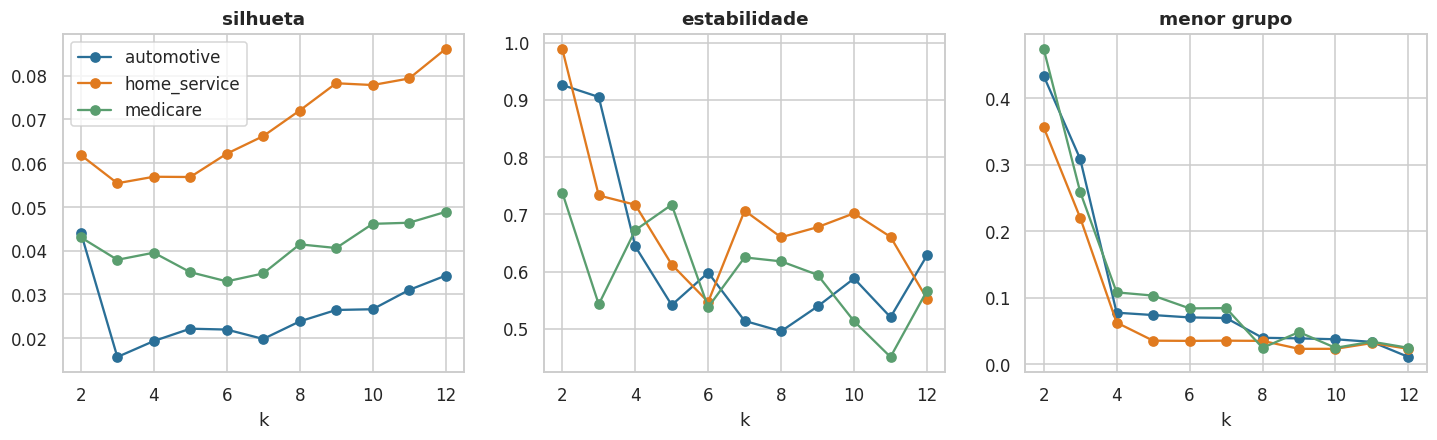

setor,automotive,home_service,medicare
k,,,
2,0.93,0.99,0.74
3,0.90,0.73,0.54
4,0.64,0.72,0.67
5,0.54,0.61,0.72
6,0.60,0.55,0.54
7,0.51,0.71,0.62
8,0.50,0.66,0.62
9,0.54,0.68,0.59
10,0.59,0.70,0.51


In [48]:
k_scan_rows = []
for sector, space in spaces.items():
    for k in range(2, 13):
        labels = KMeans(k, n_init=5, random_state=RANDOM_STATE).fit_predict(space.vectors)
        k_scan_rows.append({
            "setor": sector, "k": k,
            "silhueta": silhouette_score(space.vectors, labels, sample_size=2000, random_state=RANDOM_STATE),
            "estabilidade": stability(lambda idx: KMeans(k, n_init=3, random_state=RANDOM_STATE).fit_predict(space.vectors[idx]), len(space.vectors), repeats=3),
            "menor grupo": np.bincount(labels).min() / len(labels),
        })
k_scan = pd.DataFrame(k_scan_rows)

figure, axes = plt.subplots(1, 3, figsize=(16, 4))
for axis, column in zip(axes, ["silhueta", "estabilidade", "menor grupo"]):
    for sector in SECTORS:
        part = k_scan[k_scan.setor == sector]
        axis.plot(part.k, part[column], marker="o", color=SECTOR_COLORS[sector], label=sector)
    axis.set(title=column, xlabel="k")
axes[0].legend()
plt.show()
save_figure(figure, "escolha_de_k")
display(k_scan.pivot(index="k", columns="setor", values="estabilidade").round(2))

**Leitura.** A estabilidade é alta para k = 2 (0,93 no automotivo, 0,99 no home service, 0,74 no medicare) porque dividir em dois grupos é fácil de reproduzir e diz pouco. Para k entre 4 e 12 ela fica entre 0,45 e 0,72, sem um "cotovelo" que indique um k único. Os k usados (6, 8 e 7) têm estabilidade de 0,60, 0,66 e 0,62: **moderada**. A escolha foi de julgamento, apoiada em que, nesses valores, os grupos se deixam ler e nomear (seção 5.7); não há evidência estatística forte a favor de um k específico.

### 5.3 Algoritmos diferentes, mesmo k

Cada algoritmo parte de uma ideia diferente de grupo:

| Algoritmo | Ideia |
|---|---|
| KMeans | grupos redondos em torno de um centro |
| Hierárquico (Ward) | junta, passo a passo, os pares de chamadas que menos aumentam a dispersão |
| Mistura de gaussianas | cada grupo é uma nuvem com forma própria, e a chamada tem probabilidade de pertencer a cada uma |
| DBSCAN | grupo é uma região densa; chamada isolada vira ruído e o número de grupos sai dos dados |
| NMF | cada chamada é uma soma de tópicos; o grupo é o tópico dominante |

Para os quatro primeiros usamos o mesmo k. O DBSCAN não aceita k: ele precisa de um raio (`eps`) e de um mínimo de vizinhos, e mostramos primeiro como escolher o raio.

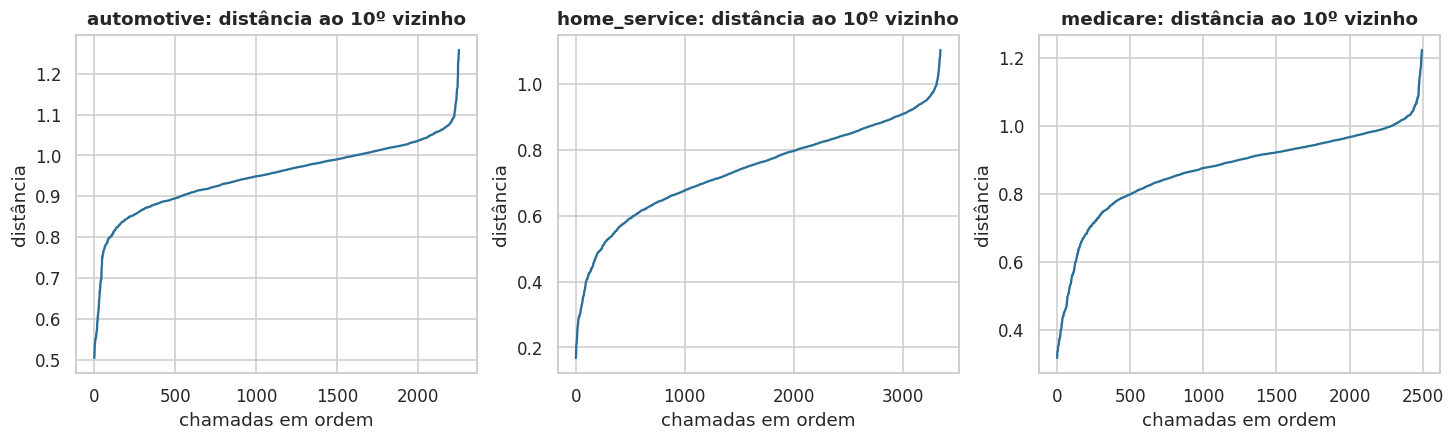

In [49]:
K_BY_SECTOR = {"automotive": 6, "home_service": 8, "medicare": 7}

figure, axes = plt.subplots(1, 3, figsize=(16, 4))
for axis, (sector, space) in zip(axes, spaces.items()):
    distances, _ = NearestNeighbors(n_neighbors=11, metric="euclidean").fit(space.vectors).kneighbors(space.vectors)
    axis.plot(np.sort(distances[:, 10]))
    axis.set(title=f"{sector}: distância ao 10º vizinho", xlabel="chamadas em ordem", ylabel="distância")
plt.show()

In [50]:
dbscan_rows = []
for sector, space in spaces.items():
    for eps in [0.45, 0.55, 0.65, 0.75, 0.85]:
        labels = DBSCAN(eps=eps, min_samples=10).fit_predict(space.vectors)
        dbscan_rows.append({"setor": sector, "eps": eps, "grupos": len(set(labels) - {-1}), "chamadas como ruído": (labels == -1).mean(),
                            "maior grupo": np.bincount(labels[labels >= 0]).max() / len(labels) if (labels >= 0).any() else 0})
display(pd.DataFrame(dbscan_rows).round(3))

,setor,eps,grupos,chamadas como ruído,maior grupo
0,automotive,0.45,1,0.996,0.004
1,automotive,0.55,2,0.990,0.005
2,automotive,0.65,4,0.977,0.006
3,automotive,0.75,6,0.963,0.009
4,automotive,0.85,12,0.701,0.189
5,home_service,0.45,14,0.911,0.023
6,home_service,0.55,30,0.796,0.028
7,home_service,0.65,43,0.559,0.047
8,home_service,0.75,33,0.287,0.215
9,home_service,0.85,5,0.059,0.921


In [51]:
EPS_BY_SECTOR = {"automotive": 0.65, "home_service": 0.65, "medicare": 0.65}  # ajustado ao ler a tabela acima


def make_label_function(algorithm, space, k):
    """Devolve uma função que recebe os índices das chamadas e devolve o grupo de cada uma."""
    def fit_labels(indices):
        if algorithm == "KMeans":
            return KMeans(k, n_init=3, random_state=RANDOM_STATE).fit_predict(space.vectors[indices])
        if algorithm == "Hierárquico (Ward)":
            return AgglomerativeClustering(k, linkage="ward").fit_predict(space.vectors[indices])
        if algorithm == "Mistura de gaussianas":
            return GaussianMixture(k, covariance_type="diag", random_state=RANDOM_STATE).fit(space.vectors[indices]).predict(space.vectors[indices])
        if algorithm == "DBSCAN":
            return DBSCAN(eps=EPS_BY_SECTOR[space.sector], min_samples=10).fit_predict(space.vectors[indices])
        if algorithm == "NMF":
            weights = NMF(k, init="nndsvda", max_iter=300, random_state=RANDOM_STATE).fit_transform(space.tfidf[indices])
            return weights.argmax(axis=1)
        raise ValueError(algorithm)
    return fit_labels


ALGORITHMS = ["KMeans", "Hierárquico (Ward)", "Mistura de gaussianas", "DBSCAN", "NMF"]
algorithm_rows = []
cluster_labels = {}
for sector, space in spaces.items():
    cluster_labels[sector] = {}
    everyone = np.arange(len(space.vectors))
    for algorithm in ALGORITHMS:
        fit_labels = make_label_function(algorithm, space, K_BY_SECTOR[sector])
        labels = fit_labels(everyone)
        cluster_labels[sector][algorithm] = labels
        clustered = labels >= 0
        algorithm_rows.append({
            "setor": sector, "algoritmo": algorithm,
            "grupos": len(set(labels) - {-1}), "chamadas como ruído": 1 - clustered.mean(),
            "silhueta": silhouette_score(space.vectors[clustered], labels[clustered], sample_size=2000, random_state=RANDOM_STATE) if len(set(labels[clustered])) > 1 else np.nan,
            "estabilidade": stability(fit_labels, len(everyone), repeats=3),
            "concordância com KMeans (ARI)": adjusted_rand_score(cluster_labels[sector]["KMeans"], labels),
        })
algorithm_table = pd.DataFrame(algorithm_rows)
display(algorithm_table.round(3))

,setor,algoritmo,grupos,chamadas como ruído,silhueta,estabilidade,concordância com KMeans (ARI)
0,automotive,KMeans,6,0.000,0.022,0.598,1.000
1,automotive,Hierárquico (Ward),6,0.000,0.014,0.335,0.296
2,automotive,Mistura de gaussianas,6,0.000,0.012,0.555,0.362
3,automotive,DBSCAN,4,0.977,0.543,0.376,0.004
4,automotive,NMF,6,0.000,0.043,0.678,0.319
5,home_service,KMeans,8,0.000,0.072,0.660,1.000
6,home_service,Hierárquico (Ward),8,0.000,0.060,0.653,0.483
7,home_service,Mistura de gaussianas,8,0.000,0.049,0.494,0.398
8,home_service,DBSCAN,43,0.559,0.321,0.843,0.127
9,home_service,NMF,8,0.000,0.068,0.616,0.636


**Leitura.**
- **DBSCAN** marca como ruído 97,7%, 55,9% e 89,0% das chamadas nos três setores, no raio escolhido. A silhueta alta dele (0,54, 0,32 e 0,49) descreve só o pequeno núcleo que agrupou, não serve para segmentar todas as chamadas.
- **KMeans, Ward, mistura de gaussianas e NMF** dão partições que concordam pouco entre si (ARI de 0,26 a 0,64 com o KMeans) e estabilidade de 0,34 a 0,75. O **NMF é igual ou mais estável em dois setores** (automotivo 0,678 contra 0,598; medicare 0,750 contra 0,625).
- Não há vencedor claro. O KMeans fica porque atribui uma chamada nova por distância a um centro, e devolve a margem para o segundo grupo, que é o que a API usa. O NMF é candidato a avaliar.

### 5.4 O mapa em duas dimensões

O UMAP leva os vetores de 100 dimensões para um plano preservando quem é vizinho de quem. Não é uma medida, é um olhar: serve para ver se os grupos do KMeans ocupam regiões distintas ou se estão misturados, e onde o DBSCAN enxerga ilhas.

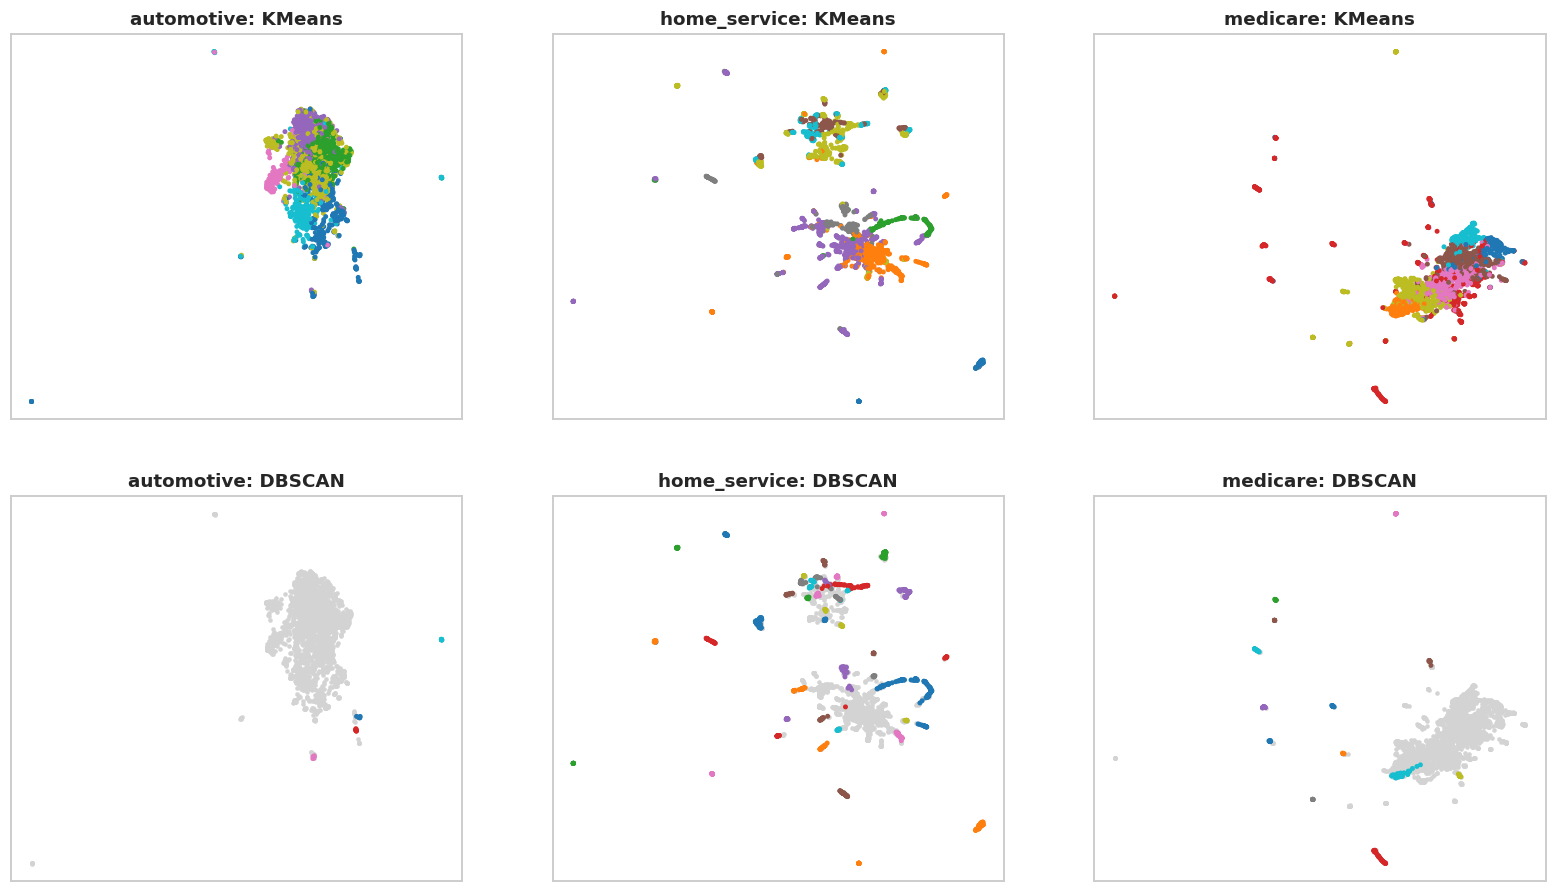

In [52]:
import umap

umap_coordinates = {}
figure, axes = plt.subplots(2, 3, figsize=(18, 10))
for column, (sector, space) in enumerate(spaces.items()):
    umap_coordinates[sector] = umap.UMAP(n_neighbors=30, min_dist=0.1, metric="cosine", random_state=RANDOM_STATE).fit_transform(space.vectors)
    for row, algorithm in enumerate(["KMeans", "DBSCAN"]):
        labels = cluster_labels[sector][algorithm]
        axes[row, column].scatter(*umap_coordinates[sector][labels == -1].T, s=4, c="lightgray", label="ruído")
        scatter = axes[row, column].scatter(*umap_coordinates[sector][labels >= 0].T, s=5, c=labels[labels >= 0], cmap="tab10")
        axes[row, column].set(title=f"{sector}: {algorithm}", xticks=[], yticks=[])
plt.show()
save_figure(figure, "mapa_umap_subgrupos")

### 5.5 Vizinhos mais próximos

Se os grupos são reais, os vizinhos mais próximos de uma chamada devem estar, na maioria, no mesmo grupo. Para cada chamada, olhamos as 10 mais parecidas e contamos a fração que cai no mesmo grupo do KMeans (**pureza de vizinhança**).

Depois verificamos chamadas **novas**: as de teste, que não participaram do agrupamento. A fração de chamadas de teste em que o grupo atribuído pelo centro mais próximo é o mesmo que a maioria dos seus vizinhos de desenvolvimento diz mede se a atribuição é coerente com a vizinhança.

In [53]:
neighbor_rows, neighbor_tables = [], {}
for sector, space in spaces.items():
    labels = cluster_labels[sector]["KMeans"]
    neighbors = NearestNeighbors(n_neighbors=11, metric="cosine").fit(space.vectors)
    _, neighbor_index = neighbors.kneighbors(space.vectors)
    purity = (labels[neighbor_index[:, 1:]] == labels[:, None]).mean(axis=1)
    neighbor_tables[sector] = pd.Series(purity).groupby(labels).mean()

    centroids = normalize(np.vstack([space.vectors[labels == c].mean(axis=0) for c in range(K_BY_SECTOR[sector])]))
    assigned = (space.test_vectors @ centroids.T).argmax(axis=1)
    _, test_neighbor_index = neighbors.kneighbors(space.test_vectors, n_neighbors=10)
    vote = np.array([np.bincount(labels[row], minlength=K_BY_SECTOR[sector]).argmax() for row in test_neighbor_index])
    neighbor_rows.append({"setor": sector, "pureza média de vizinhança": purity.mean(),
                          "pureza do grupo mais fraco": neighbor_tables[sector].min(),
                          "chamadas de teste: centro e vizinhos concordam": (assigned == vote).mean()})
display(pd.DataFrame(neighbor_rows).round(3))

,setor,pureza média de vizinhança,pureza do grupo mais fraco,chamadas de teste: centro e vizinhos concordam
0,automotive,0.650,0.451,0.698
1,home_service,0.848,0.799,0.920
2,medicare,0.726,0.662,0.841


**Leitura.** A pureza média de vizinhança é 0,650 no automotivo, 0,848 no home service e 0,726 no medicare (o grupo mais fraco de cada um: 0,451, 0,799 e 0,662). Nas chamadas de teste, o centro mais próximo e o voto dos vizinhos concordam em 69,8%, 92,0% e 84,1% dos casos. O home service é o mais coeso; o automotivo é o menos separado, o que combina com sua estabilidade mais baixa: muitas chamadas de compra e de serviço se parecem.

In [54]:
example_sector = "medicare"
space = spaces[example_sector]
labels = cluster_labels[example_sector]["KMeans"]
neighbors = NearestNeighbors(n_neighbors=4, metric="cosine").fit(space.vectors)
for call_number in [3, 40]:
    distance, index = neighbors.kneighbors(space.vectors[call_number:call_number + 1])
    print(f"Chamada {call_number}, grupo {labels[call_number]}: ...{' '.join(space.dev_calls.transcript[call_number].split()[80:115])}...")
    for d, i in zip(distance[0][1:], index[0][1:]):
        print(f"   vizinho (distância {d:.2f}), grupo {labels[i]}: ...{' '.join(space.dev_calls.transcript[i].split()[80:115])}...")

(saída omitida: trechos de transcrições de terceiros não são publicados)


### 5.6 Embeddings de frase em vez de TF-IDF

O TF-IDF só enxerga as palavras que aparecem. O embedding do MiniLM tenta capturar o significado, então "my pooch needs a haircut" e "dog grooming" ficam perto mesmo sem palavra em comum. Repetimos o KMeans com o mesmo k sobre os embeddings e comparamos com o agrupamento por TF-IDF em três medidas: concordância entre as partições (ARI), estabilidade, e sobreposição dos 10 vizinhos mais próximos nas duas representações.

In [55]:
embedding_rows = []
embedding_labels = {}
for sector, space in spaces.items():
    k = K_BY_SECTOR[sector]
    unit_embeddings = normalize(space.embeddings)
    labels = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(unit_embeddings)
    embedding_labels[sector] = labels
    tfidf_neighbors = NearestNeighbors(n_neighbors=11, metric="cosine").fit(space.vectors).kneighbors(space.vectors)[1][:, 1:]
    embedding_neighbors = NearestNeighbors(n_neighbors=11, metric="cosine").fit(unit_embeddings).kneighbors(unit_embeddings)[1][:, 1:]
    overlap = np.mean([len(set(a) & set(b)) / 10 for a, b in zip(tfidf_neighbors, embedding_neighbors)])
    embedding_rows.append({
        "setor": sector, "k": k,
        "ARI entre TF-IDF e embedding": adjusted_rand_score(cluster_labels[sector]["KMeans"], labels),
        "estabilidade TF-IDF": algorithm_table[(algorithm_table.setor == sector) & (algorithm_table.algoritmo == "KMeans")].estabilidade.iloc[0],
        "estabilidade embedding": stability(lambda idx: KMeans(k, n_init=3, random_state=RANDOM_STATE).fit_predict(unit_embeddings[idx]), len(unit_embeddings), repeats=3),
        "vizinhos em comum (de 10)": overlap * 10,
    })
embedding_table = pd.DataFrame(embedding_rows)
display(embedding_table.round(3))

,setor,k,ARI entre TF-IDF e embedding,estabilidade TF-IDF,estabilidade embedding,vizinhos em comum (de 10)
0,automotive,6,0.200,0.598,0.771,1.147
1,home_service,8,0.279,0.660,0.791,1.254
2,medicare,7,0.172,0.625,0.567,1.374


**Leitura.** O acordo entre as partições por TF-IDF e por embedding é baixo (ARI de 0,200, 0,279 e 0,172) e os dois só têm entre 1,1 e 1,4 vizinhos em comum entre os 10 mais próximos: as representações discordam sobre quem se parece com quem. A estabilidade do embedding (0,771, 0,791 e 0,567) é maior que a do TF-IDF (0,598, 0,660 e 0,625) no automotivo e no home service, e menor no medicare. Sem gabarito não dá para dizer qual está certa. Ficamos com o TF-IDF porque cada grupo se explica por termos que se leem (ADR 0001); o embedding segue como linha de pesquisa, por exemplo um modelo híbrido para o automotivo.

### 5.7 Lendo os grupos e validando com temas independentes

Para cada grupo do KMeans sobre TF-IDF: tamanho, termos de maior peso, e um trecho de exemplo da chamada mais central. Depois uma validação que não depende dos termos usados para nomear: cruzar cada grupo com palavras-chave de temas definidos à parte (por exemplo, se um grupo for de URA, `press` deve aparecer nele bem mais do que nos outros).

In [56]:
for sector, space in spaces.items():
    labels = cluster_labels[sector]["KMeans"]
    print(f"===== {sector} (k={K_BY_SECTOR[sector]})")
    centroids = normalize(np.vstack([space.vectors[labels == c].mean(axis=0) for c in range(K_BY_SECTOR[sector])]))
    for cluster in range(K_BY_SECTOR[sector]):
        members = np.where(labels == cluster)[0]
        central = members[np.argmax(space.vectors[members] @ centroids[cluster])]
        snippet = " ".join(space.dev_calls.transcript[central].split()[60:100])
        print(f"[{cluster}] {len(members):4d} chamadas ({len(members) / len(labels):.0%}) | {', '.join(space.top_terms(labels, cluster, 10))}")
        print(f"      exemplo: ...{snippet}...")

(saída omitida: trechos de transcrições de terceiros não são publicados)


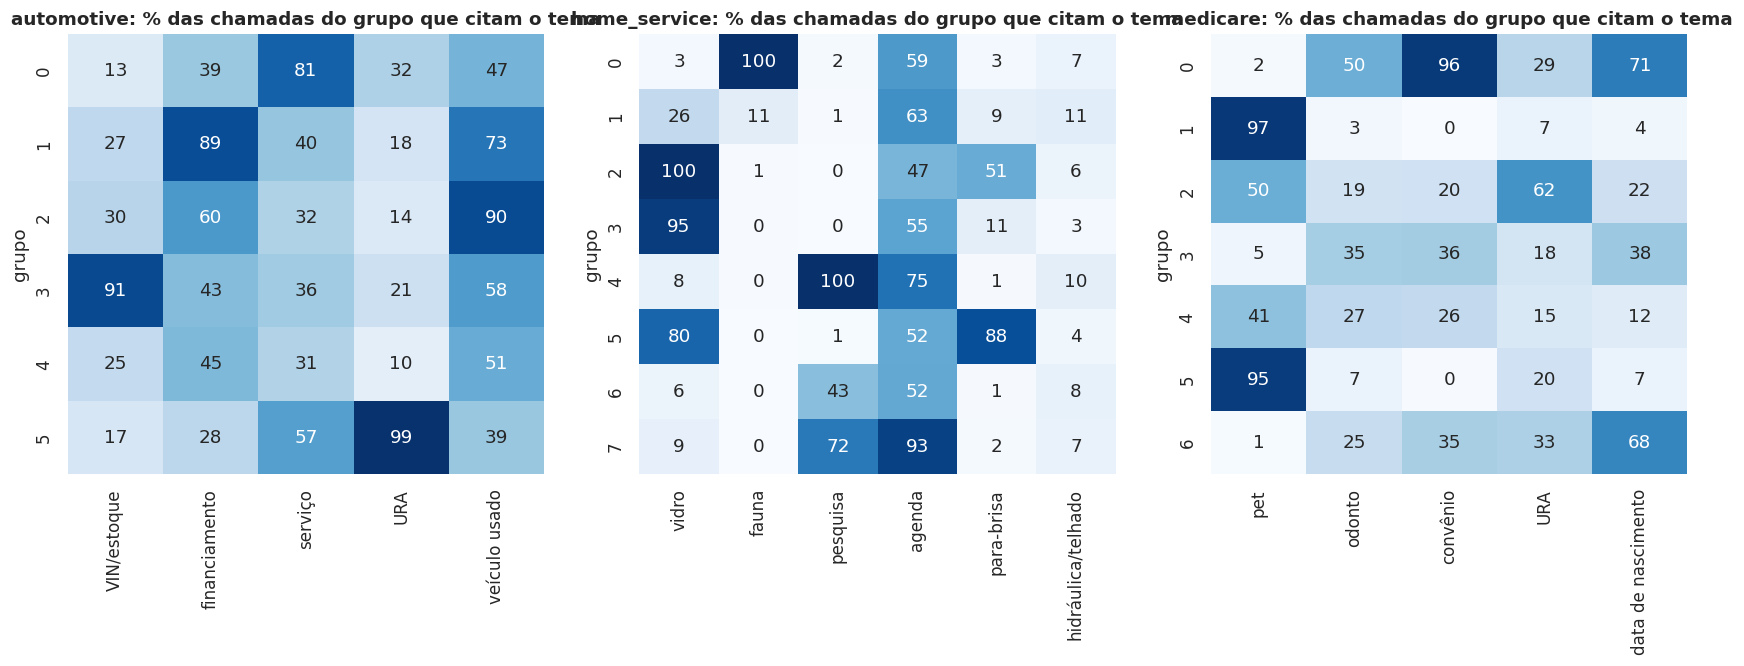

In [57]:
THEMES = {
    "automotive": {"VIN/estoque": r"\b(?:vin|stock number)\b", "financiamento": r"\b(?:credit|payment|lease|financ\w*|trade)\b",
                   "serviço": r"\b(?:appointment|oil change|service)\b", "URA": r"\b(?:press|extension)\b",
                   "veículo usado": r"\b(?:used|color|miles|test drive)\b"},
    "home_service": {"vidro": r"\b(?:glass|window\w*)\b", "fauna": r"\b(?:wildlife|animals?)\b", "pesquisa": r"\b(?:satisfied|survey|feedback)\b",
                     "agenda": r"\b(?:tomorrow|appointment|schedule)\b", "para-brisa": r"\b(?:windshield|insurance)\b",
                     "hidráulica/telhado": r"\b(?:plumb\w*|roof\w*|toilet|faucet)\b"},
    "medicare": {"pet": r"\b(?:dogs?|pets?|puppy|boarding|grooming|daycare)\b", "odonto": r"\b(?:dental|teeth|tooth|cleaning)\b",
                 "convênio": r"\b(?:insurance|member id|copay)\b", "URA": r"\b(?:press)\b", "data de nascimento": r"\b(?:date of birth|birth)\b"},
}
figure, axes = plt.subplots(1, 3, figsize=(19, 5.2))
theme_tables = {}
for axis, (sector, space) in zip(axes, spaces.items()):
    labels = cluster_labels[sector]["KMeans"]
    lowered = space.dev_calls.transcript.str.lower()
    presence_by_theme = pd.DataFrame({theme: lowered.str.contains(pattern, regex=True) for theme, pattern in THEMES[sector].items()})
    theme_tables[sector] = presence_by_theme.groupby(labels).mean() * 100
    sns.heatmap(theme_tables[sector], annot=True, fmt=".0f", cmap="Blues", cbar=False, vmin=0, vmax=100, ax=axis)
    axis.set(title=f"{sector}: % das chamadas do grupo que citam o tema", xlabel="", ylabel="grupo")
plt.show()
save_figure(figure, "validacao_por_temas")

**Leitura.** Em 13 dos 21 grupos um tema aparece em pelo menos 80% das chamadas (por exemplo, URA em 99% de um grupo do automotivo, fauna em 100% de um grupo do home service, convênio em 96% de um grupo do medicare). Os outros oito são grupos de conversa genérica (recepção, retorno, cortesia de encerramento, dúvidas variadas). Os temas desta validação são lexicais, o que favorece o TF-IDF por construção, então o teste não decide nada contra os embeddings.

### 5.8 Nomes dos grupos

Os nomes que a API devolve estão em `src/call_segmenter/models/subgroup_names.json`, cada um com termos-âncora que precisam aparecer no vocabulário do grupo (ADR 0003). Foram escritos lendo os termos e os trechos desta seção, depois de ajustar o agrupador com os mesmos parâmetros do pipeline de produção. São **hipóteses** sem gabarito humano.

## 6. Decisão e limitações

**O que vai para a API**

| Peça | Escolha | Por quê |
|---|---|---|
| Representação | TF-IDF de palavras e pares de palavras | empata com tudo que é mais complexo, e é legível (seções 4.4 a 4.13) |
| Setor | SVM linear calibrado | empate com o melhor, simples, rápido, probabilidade calibrada (4.13) |
| Metadados | não usados | o ganho vem do atalho de origem do áudio (4.7) |
| Aviso de baixa confiança | limiar 0,90 | maior limiar dentro do orçamento de 6% de chamadas marcadas (4.14) |
| Subgrupos | KMeans por setor, k = 6, 8 e 7, com margem e nomes por âncora | estabilidade moderada, grupos legíveis e atribuição por distância (5.2, 5.3, 5.7) |

**Limitações**
- Os subgrupos não têm gabarito: a validação é por estabilidade, vizinhança e temas, e um humano precisa confirmar se a partição serve ao negócio.
- Existe um atalho de metadados (seção 3). O texto sustenta o desempenho, mas o atalho é um risco se a origem das transcrições mudar.
- O modelo pré-treinado foi avaliado com orçamento de CPU: não representa o teto de um BERT.
- Erros de setor propagam para o subgrupo.
- O teste do caderno e o do pipeline de produção são conjuntos diferentes de chamadas.

**Próximos passos:** amostra rotulada por pessoas para validar subgrupos; BERT com GPU e chamada em trechos; avaliar o NMF como agrupador; sinal de dúvida por "nenhum ou vários detectores positivos"; deriva por vocabulário.

In [58]:
def as_records(frame):
    """Tabela do pandas como lista de dicionários simples (NaN vira null)."""
    return json.loads(frame.to_json(orient="records"))


test_rows = test_table.set_index("modelo")
metrics["setor"] = {
    "escolhido": reference_name,
    "chamadas_desenvolvimento": int(len(development)),
    "chamadas_teste": int(len(test)),
    "validacao_cruzada_referencia": {"f1_macro": float(reference_mean), "desvio": float(reference_std)},
    "familias_validacao_cruzada": as_records(family_table),
    "teste": {name: {key: (int(value) if key == "erros" else float(value)) for key, value in row.items()}
              for name, row in test_rows.to_dict("index").items()},
    "ic95_f1_macro": [float(interval[0]), float(interval[1])],
    "mcnemar_contra_svm_calibrado": as_records(pd.DataFrame(mcnemar_rows)),
    "busca_hiperparametros": {
        "grade": {"combinacoes": int(len(grid_results)), "melhor_f1": float(grid_results.mean_test_score.max()),
                  "pior_f1": float(grid_results.mean_test_score.min()), "minutos": float(grid_seconds / 60)},
        "aleatoria_mesmo_orcamento": {"combinacoes": int(len(random_same_budget)),
                                      "melhor_f1": float(random_same_budget.mean_test_score.max()),
                                      "pior_f1": float(random_same_budget.mean_test_score.min()),
                                      "minutos": float(random_seconds / 60)},
        "aleatoria_ampla": {"combinacoes": int(len(wide_results)), "minutos": float(wide_seconds / 60),
                            "melhor_por_familia": {row.family: float(row.mean_test_score) for row in best_per_family.itertuples()}},
    },
    "diagnostico_de_ajuste": {"curva_de_validacao": as_records(validation_curve),
                              "curva_de_aprendizado": {"chamadas": [int(n) for n in sizes],
                                                       "treino": [float(v) for v in train_curve.mean(axis=1)],
                                                       "validacao": [float(v) for v in valid_curve.mean(axis=1)]}},
    "limiar_baixa_confianca": {
        "escolhido": chosen_threshold, "orcamento_de_chamadas_marcadas": FLAG_BUDGET,
        "tabela": as_records(threshold_table),
        "teste": {"marcadas": float(test_flagged.mean()), "erros_capturados": int((test_flagged & test_wrong).sum()),
                  "erros": int(test_wrong.sum())},
    },
    "palavras_necessarias": {str(row["palavras lidas"]): float(row["F1 macro"]) for row in truncation_rows},
    "termos_que_pesam": heaviest_terms,
    "modelos_pre_treinados": {"distilbert_f1_primeira_dobra": float(bert_valid_f1),
                              "svm_f1_primeira_dobra": float(svm_first_fold.valid_f1.iloc[0]),
                              "minilm_f1_validacao_cruzada": float(embedding_scores.valid_f1.mean()),
                              "distilbert_minutos_de_ajuste": float(bert_run["training_seconds"] / 60)},
    "detectores_por_setor": as_records(detector_table),
}
metrics["subgrupos"] = {
    "k": K_BY_SECTOR,
    "escolha_de_k": as_records(k_scan),
    "algoritmos": as_records(algorithm_table),
    "vizinhanca": neighbor_rows,
    "embeddings": as_records(embedding_table),
    "temas_por_grupo": {sector: theme_tables[sector].round(1).to_dict("index") for sector in SECTORS},
}

benchmark = {
    "split": {"desenvolvimento": int(len(development)), "teste": int(len(test)), "dobras": 5},
    "lazy": [{"model": r["Model"], "f1_macro": r["F1 macro"], "accuracy": r["Accuracy"], "seconds": r["Time Taken"]}
             for r in lazy_scores.to_dict("records")],
    "families_cv": [{"model": r["modelo"], "f1_validation": r["F1 validação"], "std": r["desvio"],
                     "f1_train": r["F1 treino"], "fit_seconds": r["segundos por ajuste"]}
                    for r in family_table.to_dict("records")],
    "wide_random_search": [{"family": r["family"], "f1_macro": r["mean_test_score"], "std": r["std_test_score"],
                            "fit_seconds": r["mean_fit_time"],
                            "parameters": {k: (list(v) if isinstance(v, tuple) else v) for k, v in r["parameters"].items()}}
                           for r in wide_results.sort_values("mean_test_score", ascending=False).to_dict("records")],
    "test": [{"model": r["modelo"], "f1_macro": r["F1 macro"], "errors": r["erros"], "accuracy": r["acurácia"], "ece": r["ECE"]}
             for r in test_table.to_dict("records")],
}
REPORTS_DIR.mkdir(exist_ok=True)
(REPORTS_DIR / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=1, default=str))
(REPORTS_DIR / "benchmark.json").write_text(json.dumps(benchmark, ensure_ascii=False, indent=1, default=str))
print("gravados:", sorted(path.name for path in REPORTS_DIR.glob("*.json")))

gravados: ['benchmark.json', 'metrics.json']
